In [1]:
%matplotlib inline

from collections import OrderedDict
from importlib import reload
import os, sys

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec

import numpy as np
import pandas as pd
import scipy.stats

from astropy.table import Table, vstack, hstack, join, Column
from astropy.stats import mad_std
from astropy.constants import iau2012 as const

from scipy.stats import spearmanr, gaussian_kde
import statsmodels.api as sm

sys.path.append('../')
from aklpyutils.utils_stats import *

# sys.path.append(os.path.join(os.getenv('HOME'),'python'))

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MaxNLocator
from shapely.geometry import Point
from shapely.ops import cascaded_union

from jsplottools.sun_plot_tools.general import mpl_setup
from jsplottools.sun_plot_tools.ax import *
from jsplottools.sun_plot_tools.fig import *
mpl_setup(figtype='paper-1/3')
params = {'legend.fontsize': 'x-large',          
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
plt.rcParams.update(params)

from astropy.io import ascii

In [2]:
from importlib import reload
from key_dirs import *
from aklpyutils.utils_spacing import *


print(source_list)

def get_source_list(folder):
    temp_source_list = os.listdir(folder)
    temp_source_list.sort()
    source_list = []
    for this_source_file in temp_source_list:
        this_source = this_source_file.split('_')[0]
        source_list.append(this_source)
        source_array = np.unique(np.array(source_list))

    return source_array

def agregt_bins(cross_dict, source_list, statistics='I_median', model='model'):
    bins_xgeo = cross_dict['ic1954']['real']['bins_xmid']
    nbins = len(bins_xgeo)
    corr_agg_16 = np.zeros_like(bins_xgeo)*np.nan
    corr_agg_50 = np.zeros_like(bins_xgeo)*np.nan
    corr_agg_84 = np.zeros_like(bins_xgeo)*np.nan
    corr_agg_errlo = np.zeros_like(bins_xgeo)*np.nan
    corr_agg_errhi = np.zeros_like(bins_xgeo)*np.nan

    for ii in range(nbins):

        # Extract vectors for this bin
        corr_bin_list = []

        for this_source in source_list:
            this_entry = cross_dict[this_source]
            real_coeff = np.array(this_entry['real'][statistics])[ii] / this_entry['real'][statistics][0]
            model_coeff = np.array(this_entry[model][statistics])[ii]  / this_entry[model][statistics][0]
            corr_bin_list.append(real_coeff/model_coeff)
        
        corr_bin_arr = np.array(corr_bin_list)

        # Caclulate perecentiles and save results
        vec = corr_bin_arr
        corr_agg_16[ii] = np.nanpercentile(vec,16)
        corr_agg_50[ii] = np.nanpercentile(vec,50)
        corr_agg_84[ii] = np.nanpercentile(vec,84)
        n_fin = np.sum(np.isfinite(vec))
        corr_agg_errlo[ii] = \
            (np.nanpercentile(vec,50) - np.nanpercentile(vec,16))/np.sqrt(n_fin)
        corr_agg_errhi [ii]= \
            (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)
    print(n_fin)
    return bins_xgeo, corr_agg_16, corr_agg_50, corr_agg_84, corr_agg_errlo, corr_agg_errhi

['ic1954', 'ic5273', 'ngc0253', 'ngc0300', 'ngc0628', 'ngc0685', 'ngc1097', 'ngc1511', 'ngc1546', 'ngc1637', 'ngc1792', 'ngc2903', 'ngc2997', 'ngc3137', 'ngc3351', 'ngc3489', 'ngc3511', 'ngc3521', 'ngc3621', 'ngc3627', 'ngc4254', 'ngc4298', 'ngc4459', 'ngc4476', 'ngc4477', 'ngc4536', 'ngc4548', 'ngc4569', 'ngc4596', 'ngc4731', 'ngc4781', 'ngc4826', 'ngc4941', 'ngc5068', 'ngc5128', 'ngc5236', 'ngc5643', 'ngc7456', 'ngc7496', 'ngc7793']
['ic1954', 'ic5273', 'ngc0253', 'ngc0300', 'ngc0628', 'ngc0685', 'ngc1097', 'ngc1511', 'ngc1546', 'ngc1637', 'ngc1792', 'ngc2903', 'ngc2997', 'ngc3137', 'ngc3351', 'ngc3489', 'ngc3511', 'ngc3521', 'ngc3621', 'ngc3627', 'ngc4254', 'ngc4298', 'ngc4459', 'ngc4476', 'ngc4477', 'ngc4536', 'ngc4548', 'ngc4569', 'ngc4596', 'ngc4731', 'ngc4781', 'ngc4826', 'ngc4941', 'ngc5068', 'ngc5128', 'ngc5236', 'ngc5643', 'ngc7456', 'ngc7496', 'ngc7793']


## Load the data

In [4]:
cross_dict = {}
# indir = '../cloud_cats_fits/homogen_150pc_low_noise/'
indir = '../cross_results/'
# indir = '../cross_results_temp/'
# indir = '../cross_results_log/'
# indir = '../cross_results_90pc/'

# exclude wierd galaxies in the source list
# get the weird sources based on the flux recovery fraction
gal_propt = ascii.read('../Leroy_PHANGS_galaxies.txt')
for i, name in enumerate(gal_propt['Galaxy']):
    gal_propt['Galaxy'][i] = (gal_propt['Galaxy'][i].lower()).replace(" ", "")

index_map = {name: idx for idx, name in enumerate(sample_tab['name'])}
new_order_indices = [index_map[name] for name in gal_propt['Galaxy'] if name in index_map.keys()]

if 'f_recvr' not in sample_tab.columns:
    sample_tab.add_column(np.nan, name='f_recvr')
if 'faint_lab' not in sample_tab.columns:
    sample_tab.add_column(' ', name='faint_lab')
for i in range(len(gal_propt)):
    sample_tab['f_recvr'][new_order_indices[i]] = gal_propt['Comp2'][i]
    sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]

sample_tab[['f_recvr', 'faint_lab']]

source_weird = []
for i, source in enumerate(sample_tab['name']):
    if sample_tab['faint_lab'][i] == 'F':
        source_weird.append(source)
# source_weird.append('ngc0300')

source_nthresh = ['ngc0300','ngc3489','ngc4459', 'ngc4476', 'ngc4477', 'ngc4596', 'ngc4731', 'ngc4826', 'ngc7456', 'ngc7793']

# print(source_weird)
# source_weird = ['ngc0300','ngc0685','ngc3489','ngc7456','ngc7793', 'ngc5128']
# source_weird.append('ngc4596')
# source_weird = ['ngc0300']
# source_small_num = ['ngc0300', 'ngc3489', 'ngc4459', 'ngc4476', 'ngc4596', 'ngc4826']
# source_list = [source for source in source_list if source not in source_small_num]

first = True
for this_source in source_list:
    
    # Load files
    real_tab = Table.read(indir+this_source+'_realcross.fits')
    mock_tab = Table.read(indir+this_source+'_modelcross.fits')
    mockbeam_tab = Table.read(indir+this_source+'_modelbeam.fits')
    
    cross_dict[this_source] = {
        'real':real_tab,
        'model':mock_tab,
        'modelbeam': mockbeam_tab,
    }
    
    #print(this_source, corr_dict[this_source]['nclouds'])

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1146161488.py:23: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1146161488.py:23: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1146161488.py:23: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = gal_propt['f_Comp2'][i]
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1146161488.py:23: StringTruncateWarning: truncated right side string(s) longer than 1 character(s) during assignment
  sample_tab['faint_lab'][new_order_indices[i]] = 

In [5]:
bins_xgeo = cross_dict['ic1954']['real']['bins_xmid']
nbins = len(bins_xgeo)
corr_agg_16 = np.zeros_like(bins_xgeo)*np.nan
corr_agg_50 = np.zeros_like(bins_xgeo)*np.nan
corr_agg_84 = np.zeros_like(bins_xgeo)*np.nan
corr_agg_errlo = np.zeros_like(bins_xgeo)*np.nan
corr_agg_errhi = np.zeros_like(bins_xgeo)*np.nan

for ii in range(nbins):

    # Extract vectors for this bin
    corr_bin_list = []
    
    for this_source in source_list:
        this_entry = cross_dict[this_source]
        real_coeff = this_entry['real']['y_median'][ii] / this_entry['real']['y_median'][0]
        model_coeff = this_entry['model']['y_median'][ii] / this_entry['model']['y_median'][0]
        corr_bin_list.append(real_coeff/model_coeff)
        
    corr_bin_arr = np.array(corr_bin_list)
    
    # Caclulate perecentiles and save results
    vec = corr_bin_arr
    corr_agg_16[ii] = np.nanpercentile(vec,16)
    corr_agg_50[ii] = np.nanpercentile(vec,50)
    corr_agg_84[ii] = np.nanpercentile(vec,84)
    n_fin = np.sum(np.isfinite(vec))
    corr_agg_errlo[ii] = \
        (np.nanpercentile(vec,50) - np.nanpercentile(vec,16))/np.sqrt(n_fin)
    corr_agg_errhi [ii]= \
        (np.nanpercentile(vec,84) - np.nanpercentile(vec,50))/np.sqrt(n_fin)

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_17860/2178417477.py:20: UserWarning: Warning: converting a masked element to nan.
  corr_bin_arr = np.array(corr_bin_list)


Check the cloud radial profile for individual galaxies

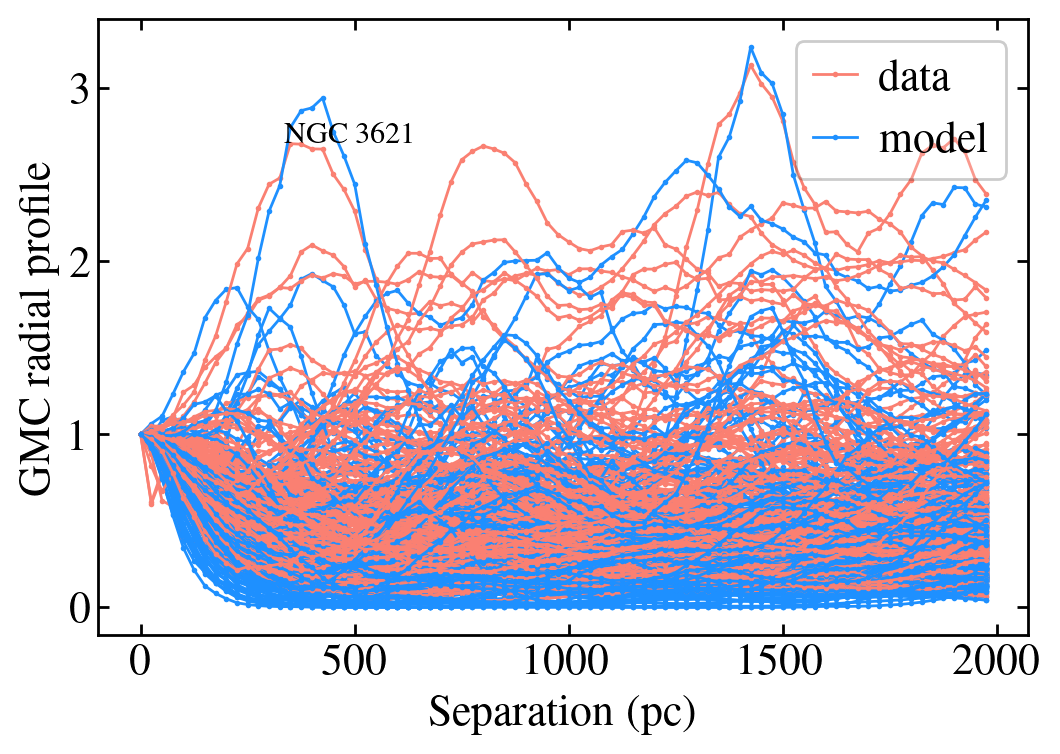

In [5]:
# check NGC 3621

cloud_rad_profl = Table.read('../cloud_radial_profile/ngc3621_150pc_hi_cat.fits')

fig = plt.figure(figsize=(6,4))
ax = plt.subplot(111)
plt.xlabel('Separation (pc)'); plt.ylabel('GMC radial profile')
for i in range(len(cloud_rad_profl)):
    plt.plot(cloud_rad_profl['radial_bins'][i], cloud_rad_profl['radial_real_val'][i]/cloud_rad_profl['radial_real_val'][i][0], color='salmon', marker='o')
    plt.plot(cloud_rad_profl['radial_bins'][i], cloud_rad_profl['radial_model_val'][i]/cloud_rad_profl['radial_model_val'][i][0], color='dodgerblue', marker='o')
ax.annotate('NGC 3621', (0.2, 0.8), xycoords='axes fraction', color='black')
plt.plot([], [], marker='o', color='salmon', label='data')
plt.plot([], [], marker='o', color='dodgerblue', label='model')
plt.legend()
plt.savefig('../plots/NGC3621_individual_cloud_profile.png', bbox_inches='tight')

## Main Analyses

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/229499090.py:10: RuntimeWarning: divide by zero encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/229499090.py:10: RuntimeWarning: invalid value encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,


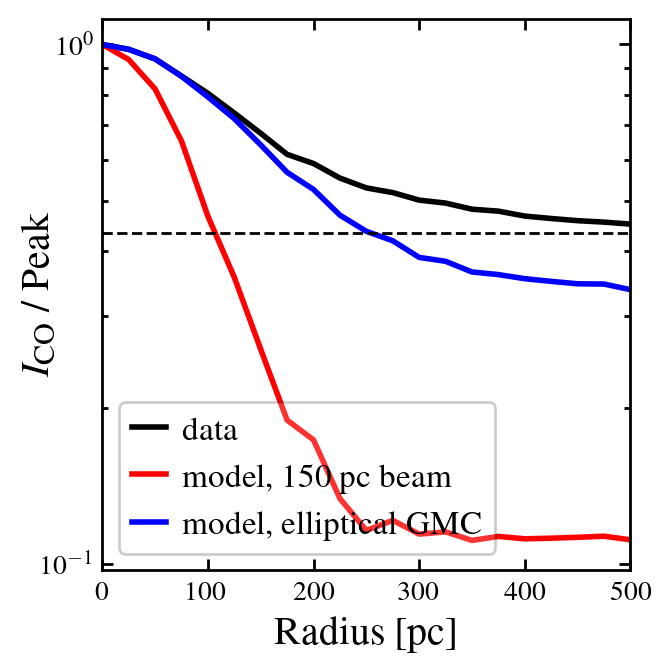

In [6]:
%matplotlib inline
# stack the gmcs to have the 
gmc_stacked = Table()
for i, this_source in enumerate(source_list):
    infile_name = '../cloud_rad_profl_Tmax_vdep/'+this_source+'_150pc_hi_cat.fits'
    gmc_rad_tabl = Table.read(infile_name)
    gmc_stacked = vstack([gmc_stacked, gmc_rad_tabl])

real = np.array(gmc_stacked['radial_real_val'])
y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
real_median = np.nanmedian(real, axis=0)
y_real_median = np.nanmedian(y_real, axis=0)
# Get the median background
real_med = np.array(gmc_stacked['radial_real_median'])

# calculate the error
y_real_16th = np.nanpercentile(y_real, 16, axis=0)
y_real_84th = np.nanpercentile(y_real, 84, axis=0)
y_real_err_lo = 1.253*(y_real_median - y_real_16th) / np.sqrt(np.shape(y_real)[0])
y_real_err_hi = 1.253*(y_real_84th - y_real_median) / np.sqrt(np.shape(y_real)[0])

# add the 1kpc radial profile
model_1kpc = np.array(gmc_stacked['radial_val_model_1kpc']); model_median_1kpc = np.nanmedian(model_1kpc, axis=0)

# model convolving with a fixed beam size
model_150pc = np.array(gmc_stacked['radial_modelbeam_val'])
y_mod_150pc = model_150pc / np.repeat(model_150pc[:,0][:, None], 80, axis=1)
model_150pc_median = np.nanmedian(model_150pc, axis=0)
y_mod_150pc_median = np.nanmedian(y_mod_150pc, axis=0)
# model convolving with measured GMC size
model_gmc_rad = np.array(gmc_stacked['radial_model_val'])
y_mod_gmc_rad = model_gmc_rad / np.repeat(model_gmc_rad[:,0][:, None], 80, axis=1)
model_gmc_rad_median = np.nanmedian(model_gmc_rad, axis=0)
y_mod_gmc_rad_median = np.nanmedian(y_mod_gmc_rad, axis=0)
# model convolving with GMC elliptical beam
model_elptc = np.array(gmc_stacked['radial_model_elptc_val'])
y_mod_elptc = model_elptc / np.repeat(model_elptc[:,0][:, None], 80, axis=1)
model_elptc_median = np.nanmedian(model_elptc, axis=0)
y_mod_elptc_median = np.nanmedian(y_mod_elptc, axis=0)


mpl_setup('paper-1/2', aspect=4.2/4., fs=12)
# fig, axes = plt.subplots(nrows=1, ncols=1, gridspec_kw={'wspace': 0.25})
fig = plt.figure()
# ax = axes[0]
# ax.set_yscale('log')
# ax.set_xlabel('Radius [pc]'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ [K km/s]', labelpad=-5)
# # plot the real radial profile
# ax.plot(gmc_stacked['radial_bins'][0], real_median, color='black', label='data', lw=2)
# # plot the model median with fixed beam
# ax.plot(gmc_stacked['radial_bins'][0], model_150pc_median, color='red', label='model, 150 pc beam', lw=2)
# # # plot the model median convolved with GMC size
# # ax.plot(gmc_stacked['radial_bins'][0], model_gmc_rad_median, color='green', label='model, circular GMC', lw=2, ls='dashed')
# # plot the model convolved with elliptical GMC size
# ax.plot(gmc_stacked['radial_bins'][0], model_elptc_median, color='blue', label='model, elliptical GMC', lw=2)
# # plot the average background 
# bkg_arr = np.nanmedian(real[:, 20:40], axis=1)
# bkg=np.nanmedian(bkg_arr)
# ax.axhline(bkg, color='black', ls='dashed')
# # # plot the median background from data + mean background from model
# # bkg_arr = np.nanmedian((real_med[:,20:40]), axis=1)
# # bkg=np.nanmedian(bkg_arr)
# # ax.axhline(bkg, color='black', ls='dotted')
# ax.set_xlim(0, 500)
# # plot legend
# plt.legend(fontsize=10)

ax = plt.subplot(111)
ax.set_yscale('log')
ax.set_xlabel('Radius [pc]'); ax.set_ylabel(r"$I_{\mathrm{CO}}$ / Peak", labelpad=-5)
# plot the real radial profile
plt.plot(gmc_stacked['radial_bins'][0], y_real_median, color='black', label='data', lw=2)
# plot the model median with fixed beam
plt.plot(gmc_stacked['radial_bins'][0], y_mod_150pc_median, color='red', label='model, 150 pc beam', lw=2)
# # plot the model median convolved with GMC size
# plt.plot(gmc_stacked['radial_bins'][0], y_mod_gmc_rad_median, color='green', label='model, circular GMC', lw=2, ls='dashed')
# plot the model convolved with elliptical GMC size
plt.plot(gmc_stacked['radial_bins'][0], y_mod_elptc_median, color='blue', label='model, elliptical GMC', lw=2)
# plot the background
y_bkg_arr = np.nanmedian(y_real[:, 20:40], axis=1)
y_bkg = np.nanmedian(y_bkg_arr)
ax.axhline(y_bkg, color='black', ls='dashed')
ax.set_xlim(0, 500)
# plot legend
plt.legend(fontsize=12, loc='lower left')

# plt.subplots_adjust(wspace=0.3)
# make the title
# plt.suptitle('All galaxies, 150 pc, high sensitivity') 
plt.savefig('../plots/radial_profile_model_comparison_onepanel.png', bbox_inches='tight')


single gaussian parameters: [  0.52628794 109.7329132 ]
double gaussian parameters: [3.80028377e-01 8.97533545e+01 1.76663746e-01 2.02357142e+02] [ 0.02351249  2.39896125  0.0189712  18.00545512]
single gaussian parameters: [  0.64531439 119.22347617]
double gaussian parameters: [  0.34003175  94.10603349   0.31970177 157.18533261] [ 0.08290013  6.16679359  0.08032396 12.50546773]


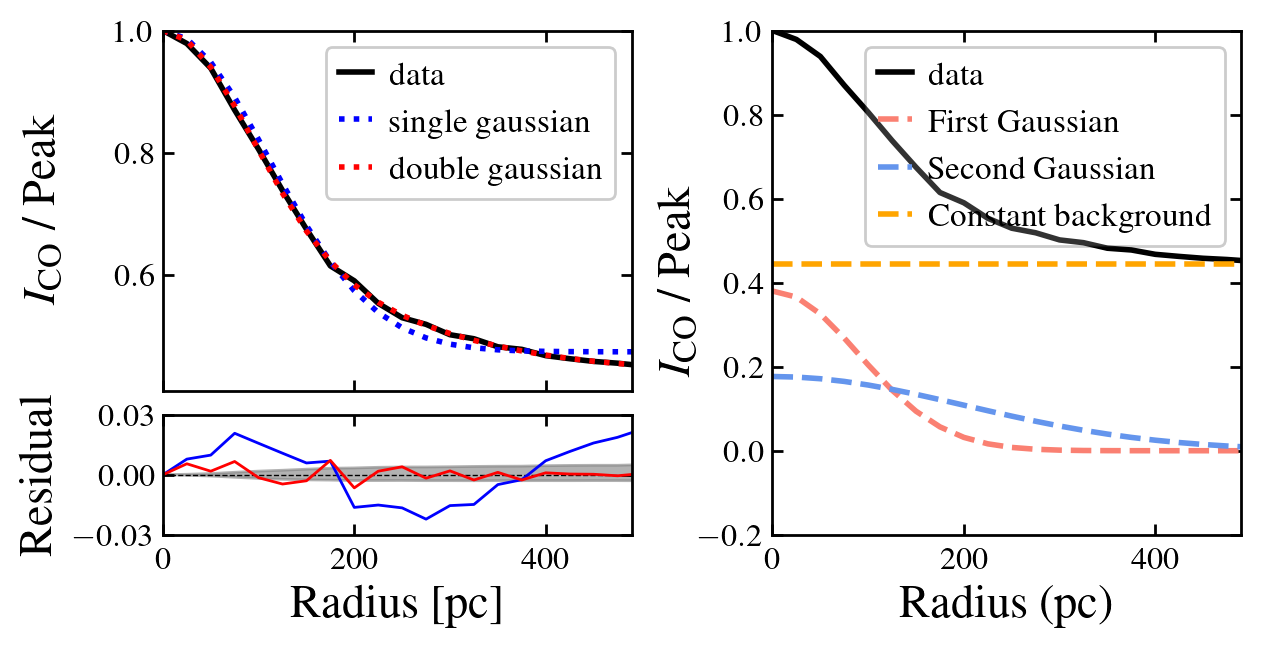

In [7]:
# create a table to store the fit parameters
fit_params_tab = Table(names=('A1', 'sigma1', 'A2', 'sigma2', 'C', 'A1_err', 'sigma1_err', 'A2_err', 'sigma2_err', 'C_err'),
                        dtype=('f4', 'f4', 'f4', 'f4', 'f4', 'f4', 'f4', 'f4', 'f4', 'f4'))

# fit a relation to the data
radial_bins = gmc_stacked['radial_bins'][0]
def gaussian_func(x, a, b):
    return a * np.exp(-x**2/2/b**2)+1-a
popt, pcov = curve_fit(gaussian_func, radial_bins[:21], y_real_median[:21], p0=[0.5, 120])
print('single gaussian parameters:', popt)
y_real_median_fit = gaussian_func(radial_bins, *popt)
def double_gaussian_func(x, a, b, c, d):
    return a * np.exp(-x**2/2/b**2) + c * np.exp(-x**2/2/d**2) + 1 - a - c
popt, pcov = curve_fit(double_gaussian_func, radial_bins[:21], y_real_median[:21], p0=[0.4, 95, 0.2, 200])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters:', popt, np.sqrt(np.diag(pcov)))
y_real_median_fit2 = double_gaussian_func(radial_bins, *popt)
y_real_median_comp1 = popt[0] * np.exp(-radial_bins**2/2/popt[1]**2)
y_real_median_comp2 = popt[2] * np.exp(-radial_bins**2/2/popt[3]**2)
y_real_median_comp3 = np.full(np.shape(radial_bins), fill_value=(1-popt[0]-popt[2]))
# def exp_func(x, a, b):
#     return a * np.exp(-x/b) + 1 - a
# popt, pcov = curve_fit(exp_func, radial_bins[:40], y_real_median[:40], p0=[0.8, 150])
# print('exponential parameters:', popt)
# y_real_median_fit3 = exp_func(radial_bins, *popt)

# fit a relation to the model
popt, pcov = curve_fit(gaussian_func, radial_bins[:21], y_mod_elptc_median[:21], p0=[0.66, 120])
print('single gaussian parameters:', popt)
y_mod_median_fit = gaussian_func(radial_bins, *popt)
popt, pcov = curve_fit(double_gaussian_func, radial_bins[:21], y_mod_elptc_median[:21], p0=[0.3, 95, 0.4, 200])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters:', popt, np.sqrt(np.diag(pcov)))
y_mod_median_fit2 = double_gaussian_func(radial_bins, *popt)
y_mod_median_fit2 = double_gaussian_func(radial_bins, *popt)
y_mod_median_comp1 = popt[0] * np.exp(-radial_bins**2/2/popt[1]**2)
y_mod_median_comp2 = popt[2] * np.exp(-radial_bins**2/2/popt[3]**2)
y_mod_median_comp3 = np.full(np.shape(radial_bins), fill_value=(1-popt[0]-popt[2]))

mpl_setup('paper-1/1', aspect=4./8.5, fs=14)
%matplotlib inline
fig = plt.figure()
# use gridspec to separate the first panel into two parts
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.3)
gs_left = gs[0].subgridspec(2,1, height_ratios=[3,1], hspace=0.1)

ax = fig.add_subplot(gs_left[0])
ax.set_ylabel(r"$I_{\mathrm{CO}}$ / Peak", labelpad=18)
ax.set_xlim(0, 490); ax.set_ylim(0.41, 1)
ax.tick_params(which='both', labelbottom=False)
ax.plot(radial_bins, y_real_median, color='black', lw=2, label='data')
# plot the fit
ax.plot(radial_bins, y_real_median_fit, color='blue', lw=2, ls='dotted', label='single gaussian')
ax.plot(radial_bins, y_real_median_fit2, color='red', lw=2, ls='dotted', label='double gaussian')
ax.legend(fontsize=12)

ax = fig.add_subplot(gs_left[1])
ax.set_xlim(0, 490); ax.set_ylim(-0.03,0.03)
ax.set_yticks([-0.03, 0, 0.03])
ax.set_xlabel('Radius [pc]'); ax.set_ylabel('Residual')
# plot the error range of the stacked profile itself
resdl_err_lo = y_real_err_lo 
resdl_err_hi = y_real_err_hi
ax.fill_between(radial_bins, -resdl_err_lo, resdl_err_hi, color='gray', alpha=0.6)
# plot the residual at the bottom
resdl1 = (y_real_median_fit - y_real_median) 
resdl2 = (y_real_median_fit2 - y_real_median)
ax.axhline(0.0, ls='dashed', lw=0.5, color='black')
ax.plot(radial_bins, resdl1, color='blue')
ax.plot(radial_bins, resdl2, color='red')

# plot the data profile
ax = fig.add_subplot(gs[1])
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r"$I_{\mathrm{CO}}$ / Peak", labelpad=0)
ax.set_xlim(0,490); ax.set_ylim(-0.2, 1)
ax.plot(radial_bins, y_real_median, color='black', lw=2, label='data')
# plot different components
ax.plot(radial_bins, y_real_median_comp1, lw=2, ls='dashed', color='salmon', label='First Gaussian')
ax.plot(radial_bins, y_real_median_comp2, lw=2, ls='dashed', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins, y_real_median_comp3, lw=2, ls='dashed', color='orange', label='Constant background')
ax.legend(fontsize=12)

# # plot the model
# ax = fig.add_subplot(gs[1])
# ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r"$I_{\mathrm{CO}}$ / Peak")
# plt.plot(radial_bins, y_mod_elptc_median, color='gray', lw=2, label='model')
# # plot different components
# plt.plot(radial_bins, y_mod_median_comp1, lw=2, ls='dashed', color='salmon', label='First Gaussian')
# plt.plot(radial_bins, y_mod_median_comp2, lw=2, ls='dashed', color='cornflowerblue', label='Second Gaussian')
# plt.plot(radial_bins, y_mod_median_comp3, lw=2, ls='dashed', color='orange', label='Constant background')
# plt.legend(fontsize=10)
plt.savefig('../plots/stack_decomposition_both.png', bbox_inches='tight', dpi=300)

Calculate the median radius of single GMC profile

Plot the stacked radial profile for the data and fit the profiles at different environments

In [8]:
def calc_rad_med(gmc_table):
    real = np.array(gmc_table['radial_real_val'])
    y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
    real_median = np.nanmedian(real, axis=0)
    y_real_median = np.nanmedian(y_real, axis=0)
    # model convolving with a fixed beam size
    model_150pc = np.array(gmc_table['radial_modelbeam_val'])
    y_mod_150pc = model_150pc / np.repeat(model_150pc[:,0][:, None], 80, axis=1)
    model_150pc_median = np.nanmedian(model_150pc, axis=0)
    y_mod_150pc_median = np.nanmedian(y_mod_150pc, axis=0)
    # model convolving with measured GMC size
    model_gmc_rad = np.array(gmc_table['radial_model_val'])
    y_mod_gmc_rad = model_gmc_rad / np.repeat(model_gmc_rad[:,0][:, None], 80, axis=1)
    model_gmc_rad_median = np.nanmedian(model_gmc_rad, axis=0)
    y_mod_gmc_rad_median = np.nanmedian(y_mod_gmc_rad, axis=0)
    # model convolving with GMC elliptical beam
    model_elptc = np.array(gmc_table['radial_model_elptc_val'])
    y_mod_elptc = model_elptc / np.repeat(model_elptc[:,0][:, None], 80, axis=1)
    model_elptc_median = np.nanmedian(model_elptc, axis=0)
    y_mod_elptc_median = np.nanmedian(y_mod_elptc, axis=0)
    # get the fraction
    frac = y_mod_elptc / y_real
    frac_med = np.nanmedian(frac, axis=0)

    return real_median, y_real_median, model_elptc_median, y_mod_elptc_median, frac_med

gmc_cats_new = Table()
for i, this_source in enumerate(source_list):
    infile_name = fid_cat_dict[this_source]
    infile_name = infile_name.replace('.fits', '_valueadded.fits')
    gal_cloud_cat = Table.read(infile_name)
    gal_rad_profl = Table.read('../cloud_rad_profl_Tmax/'+this_source+'_150pc_hi_cat.fits')
    gal_cloud_cat_new = Table.read('../cloud_cats_2024/gmc_cats_150pc_46mK/PHANGS_'+this_source+'_150pc_46mK_gmccat.fits')
    gal_cats_all = hstack([gal_cloud_cat, gal_cloud_cat_new[['SIMPLE_ENVIROFLAG']], gal_rad_profl])
    gmc_cats_new = vstack([gmc_cats_new, gal_cats_all])
# add a new column of galactic radius in the unit of effective radius. 
gmc_cats_new['RGAL_reff'] = np.full(np.shape(gmc_cats_new['GALAXY']), fill_value=np.nan)
for this_source in source_list:
    this_size = np.array(deets_dict[this_source]['size_reff'])
    row_idx = np.where(gmc_cats_new['GALAXY'] == this_source)
    gmc_cats_new['RGAL_reff'][row_idx] =  gmc_cats_new['RGAL_DEG'][row_idx]*3600./this_size

# select GMCs in the arm or interarm
# mask_arm = ((gmc_cats_new['ENV_ARM']==1) & (gmc_cats_new['ENV_DISK']==1) & (gmc_cats_new['ENV_CENTER']!=1) & (gmc_cats_new['ENV_BULGE']!=1) & (gmc_cats_new['ENV_BAR']!=1))
mask_arm = np.isin(gmc_cats_new['SIMPLE_ENVIROFLAG'], [5.,6.])
gmc_cats_arms = gmc_cats_new[mask_arm]
mask_intarm = np.isin(gmc_cats_new['SIMPLE_ENVIROFLAG'], [4.,7.,8.])
gmc_cats_intarms = gmc_cats_new[mask_intarm]
# select GMCs in the center and outskirts
gmc_cats_central = gmc_cats_new[(gmc_cats_new['RGAL_reff']<=1)]
gmc_cats_outskirts = gmc_cats_new[(gmc_cats_new['RGAL_reff']>1)]
# select GMCs in low and high kpc intensity regions
gmc_cats_high = gmc_cats_new[gmc_cats_new['peak_1kpc_val']>10**0.5]
gmc_cats_low = gmc_cats_new[gmc_cats_new['peak_1kpc_val']<=10**0.5]
# select GMCs with different masses
gmc_cats_himass = gmc_cats_new[gmc_cats_new['MLUM_MSUN']>=4e6]
gmc_cats_lomass = gmc_cats_new[gmc_cats_new['MLUM_MSUN']<4e6]
# select GMCs with different virial parameters
gmc_cats_lovir = gmc_cats_new[gmc_cats_new['VIRPARAM']<=2]
gmc_cats_hivir = gmc_cats_new[gmc_cats_new['VIRPARAM']>2]
# Exclude GMCs in center for virial parameter inspection
# gmc_cats_sub = gmc_cats_new[gmc_cats_new['SIMPLE_ENVIROFLAG']!=1]
gmc_cats_sub = gmc_cats_new[gmc_cats_new['RGAL_reff']>=0.3]
gmc_sub_lovir = gmc_cats_sub[gmc_cats_sub['VIRPARAM']<=2]
gmc_sub_hivir = gmc_cats_sub[gmc_cats_sub['VIRPARAM']>2]

# Divide the catalog by the inner and outer region
_, y_inner_median, _, _, _ = calc_rad_med(gmc_cats_central)
_, y_outer_median, _, _, _ = calc_rad_med(gmc_cats_outskirts)
# Divide the catalog by spiral arm and non-spiral arm
arm_median, y_arm_median, arm_mod_median, y_arm_mod_median, frac_arm_median = calc_rad_med(gmc_cats_arms)
intarm_median, y_intarm_median, intarm_mod_median, y_intarm_mod_median, frac_interarm_median = calc_rad_med(gmc_cats_intarms)
# Divide the catalog by high and low Ico, 1kpc region
_, y_high_median, _, _, _ = calc_rad_med(gmc_cats_high)
_, y_low_median, _, _, _ = calc_rad_med(gmc_cats_low)
# divide the catalog by GMC masses 
_, y_himass_median, _,_,_ = calc_rad_med(gmc_cats_himass)
_, y_lomass_median, _,_,_ = calc_rad_med(gmc_cats_lomass)
# divide the catalog by GMC virial parameter
_, y_lovir_median, _,_,_ = calc_rad_med(gmc_cats_lovir)
_, y_hivir_median, _,_,_ = calc_rad_med(gmc_cats_hivir)
# divide the catalog by virial parameter for non-central GMCs
_, y_lovir1_median, _,_,_ = calc_rad_med(gmc_sub_lovir)
_, y_hivir1_median, _,_,_ = calc_rad_med(gmc_sub_hivir)


/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1700554040.py:22: RuntimeWarning: divide by zero encountered in true_divide
  frac = y_mod_elptc / y_real
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1700554040.py:3: RuntimeWarning: divide by zero encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1700554040.py:3: RuntimeWarning: invalid value encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)


Calculate the 10% mass sensitivity

In [9]:
print('10% mass limit: ', np.nanpercentile(gmc_cats_new['MLUM_MSUN'],10)/1e5, 'x 10^5 solarmass')
print('10% mass limit: ', np.nanpercentile(gmc_cats_arms['MLUM_MSUN'],10)/1e5, 'x 10^5 solarmass')
print('10% mass limit: ', np.nanpercentile(gmc_cats_intarms['MLUM_MSUN'],10)/1e5, 'x 10^5 solarmass')

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4650: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  arr.partition(


10% mass limit:  8.202269727968332 x 10^5 solarmass
10% mass limit:  10.771757274932073 x 10^5 solarmass
10% mass limit:  6.490563401733841 x 10^5 solarmass


double gaussian parameters for high Ico: [2.97490528e-01 9.29665879e+01 1.76576643e-01 2.08627475e+02] [3.50178564e-02 4.41281642e+00 2.60284494e-02 3.04148438e+01]
double gaussian parameters for low Ico: [  0.42596632  82.42232599   0.22014375 157.48728317] [ 0.04012993  2.74284331  0.03768406 11.95233689]
single gaussian parameters:  [  0.47443723 110.28667702]
double gaussian parameters for inner part: [3.14596138e-01 8.72360385e+01 1.82381491e-01 1.84071006e+02] [ 0.03293006  3.70899565  0.02905505 18.00277369]
double gaussian parameters for outer part: [4.07705107e-01 9.01744847e+01 1.82759920e-01 1.95914558e+02] [ 0.02978659  2.71894376  0.02506126 19.37712378]
double gaussian parameters for arm: [4.74471818e-01 8.49248607e+01 1.33946292e-01 2.08358851e+02] [1.64069524e-02 1.44132883e+00 1.23300747e-02 2.00992716e+01]
double gaussian parameters for interarm: [  0.39970802  83.08276323   0.2088714  137.37983371] [ 0.08540223  4.85599148  0.08381102 15.81577398]


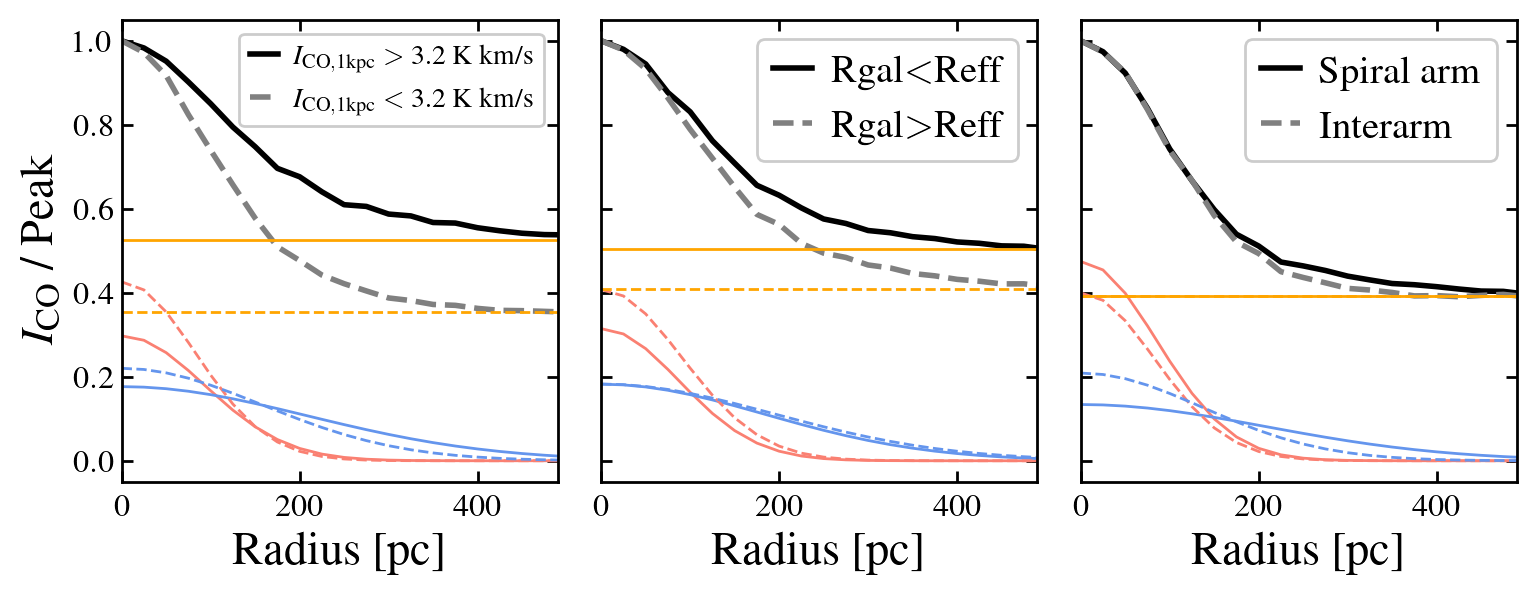

In [10]:
def fit_double_gaus(x, y, p0=[0.3, 90, 0.2, 200], bounds=([0, 25, 0.1, 25], [1, 500, 1, 500])):
    popt, pcov = curve_fit(double_gaussian_func, x, y, p0=p0, bounds=bounds)
    y_fit = double_gaussian_func(x, *popt)
    y_comp1 = popt[0] * np.exp(-x**2/2/popt[1]**2)
    y_comp2 = popt[2] * np.exp(-x**2/2/popt[3]**2)
    y_comp3 = np.full(np.shape(x), fill_value=(1-popt[0]-popt[2]))

    return y_fit, y_comp1, y_comp2, y_comp3, popt, pcov

def fit_single_gaus(x, y, p0=[0.5, 150], bounds=([0, 25], [1, 500])):
    popt, pcov = curve_fit(gaussian_func, x, y, p0=p0, bounds=bounds)
    y_fit = gaussian_func(x, *popt)
    y_comp1 = popt[0] * np.exp(-x**2/2/popt[1]**2)
    y_comp2 = np.full(np.shape(x), fill_value=(1-popt[0]))

    return y_fit, y_comp1, y_comp2, popt, pcov

%matplotlib inline
fig, axes = plt.subplots(1, 3, figsize=(9,3), sharey=True, gridspec_kw={'wspace':0.1})
axes = axes.ravel()

ax = axes[0]
ax.set_xlabel('Radius [pc]'); ax.set_ylabel(r"$I_{\mathrm{CO}}$ / Peak")
ax.set_xlim(0, 490)
ax.plot(gmc_cats_new['radial_bins'][0], y_high_median, color='black', lw=2, label=r'$I_{\mathrm{CO, 1kpc}}>$ 3.2 K km/s')
ax.plot(gmc_cats_new['radial_bins'][0], y_low_median, color='gray', ls='dashed', lw=2,  label=r'$I_{\mathrm{CO, 1kpc}}<$ 3.2 K km/s')
ax.legend(fontsize=10)

popt, pcov = curve_fit(double_gaussian_func, radial_bins[:20], y_high_median[:20], p0=[0.8, 150, 0.2, 300])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for high Ico:', popt, np.sqrt(np.diag(pcov)))
y_high_fit2 = double_gaussian_func(radial_bins, *popt)
y_high_comp1 = popt[0] * np.exp(-radial_bins**2/2/popt[1]**2)
y_high_comp2 = popt[2] * np.exp(-radial_bins**2/2/popt[3]**2)
y_high_comp3 = np.full(np.shape(radial_bins), fill_value=(1-popt[0]-popt[2]))
popt, pcov = curve_fit(gaussian_func, radial_bins[:20], y_high_median[:20], p0=[0.8, 150])
y_high_fit = gaussian_func(radial_bins, *popt)
# print('double gaussian parameters for high Ico:', popt, np.sqrt(np.diag(pcov)))
# ax.plot(radial_bins, y_high_fit2, color='red', ls='dotted')
# ax.plot(radial_bins, y_high_fit, color='blue', ls='dotted')
ax.plot(radial_bins, y_high_comp1, lw=1, ls='solid', color='salmon', label='First Gaussian')
ax.plot(radial_bins, y_high_comp2, lw=1, ls='solid', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins, y_high_comp3, lw=1, ls='solid', color='orange', label='Constant background')
# plot different components
popt, pcov = curve_fit(gaussian_func, radial_bins[:40], y_low_median[:40], p0=[0.8, 150])
# print('single gaussian parameters:', popt)
y_low_fit = gaussian_func(radial_bins, *popt)
popt, pcov = curve_fit(double_gaussian_func, radial_bins[:20], y_low_median[:20], p0=[0.3, 100, 0.2, 200])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
y_low_fit2 = double_gaussian_func(radial_bins, *popt)
print('double gaussian parameters for low Ico:', popt, np.sqrt(np.diag(pcov)))
y_low_comp1 = popt[0] * np.exp(-radial_bins**2/2/popt[1]**2)
y_low_comp2 = popt[2] * np.exp(-radial_bins**2/2/popt[3]**2)
y_low_comp3 = np.full(np.shape(radial_bins), fill_value=(1-popt[0]-popt[2]))
# ax.plot(radial_bins, y_low_fit, color='blue', ls='dotted')
# ax.plot(radial_bins, y_low_fit2, color='red', ls='dotted')
ax.plot(radial_bins, y_low_comp1, lw=1, ls='dashed', color='salmon', label='First Gaussian')
ax.plot(radial_bins, y_low_comp2, lw=1, ls='dashed', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins, y_low_comp3, lw=1, ls='dashed', color='orange', label='Constant background')


ax = axes[1]
ax.set_xlim(0,490)
ax.set_xlabel('Radius [pc]')
y_inner_fit1, _, _, popt_single, _ = fit_single_gaus(radial_bins[:21], y_inner_median[:21])
print('single gaussian parameters: ', popt_single)
y_inner_fit, y_inner_comp1, y_inner_comp2, y_inner_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_inner_median[:21])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for inner part:', popt, np.sqrt(np.diag(pcov)))
y_outer_fit, y_outer_comp1, y_outer_comp2, y_outer_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_outer_median[:21])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for outer part:', popt, np.sqrt(np.diag(pcov)))
ax.plot(radial_bins[:21], y_inner_median[:21], lw=2, ls='solid', color='black', label=r'Rgal$<$Reff')
ax.plot(radial_bins[:21], y_outer_median[:21], lw=2, ls='dashed', color='gray', label=r'Rgal$>$Reff')
# ax.plot(radial_bins[:21], y_inner_fit1, lw=1, ls='dotted', color='black')
ax.legend()
ax.plot(radial_bins[:21], y_inner_comp1, lw=1, ls='solid', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_inner_comp2, lw=1, ls='solid', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_inner_comp3, lw=1, ls='solid', color='orange', label='Constant background')
ax.plot(radial_bins[:21], y_outer_comp1, lw=1, ls='dashed', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_outer_comp2, lw=1, ls='dashed', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_outer_comp3, lw=1, ls='dashed', color='orange', label='Constant background')

ax = axes[2]
ax.set_xlim(0, 490)
ax.set_xlabel('Radius [pc]')
y_arm_fit, y_arm_comp1, y_arm_comp2, y_arm_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_arm_median[:21])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for arm:', popt, np.sqrt(np.diag(pcov)))
y_intarm_fit, y_intarm_comp1, y_intarm_comp2, y_intarm_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_intarm_median[:21])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for interarm:', popt, np.sqrt(np.diag(pcov)))
ax.plot(radial_bins[:21], y_arm_median[:21], lw=2, ls='solid', color='black', label='Spiral arm')
ax.plot(radial_bins[:21], y_intarm_median[:21], lw=2, ls='dashed', color='gray', label='Interarm')
ax.legend()
ax.plot(radial_bins[:21], y_arm_comp1, lw=1, ls='solid', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_arm_comp2, lw=1, ls='solid', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_arm_comp3, lw=1, ls='solid', color='orange', label='Constant background')
ax.plot(radial_bins[:21], y_intarm_comp1, lw=1, ls='dashed', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_intarm_comp2, lw=1, ls='dashed', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_intarm_comp3, lw=1, ls='dashed', color='orange', label='Constant background')

plt.savefig('../plots/stacked_profile_env.png', bbox_inches='tight', dpi=300)


double gaussian parameters for massive clouds: [  0.3311083   92.24767451   0.24283531 218.14132623] [ 0.02802537  3.4737322   0.02025954 19.96247385]
double gaussian parameters for low-mass clouds: [4.40176465e-01 8.74367209e+01 1.02645763e-01 1.80336145e+02] [3.21629606e-02 2.51426650e+00 2.88451535e-02 2.88908585e+01]
double gaussian parameters for bound clouds: [3.91351978e-01 9.13813195e+01 2.11177798e-01 2.20877518e+02] [2.96845224e-02 3.17286469e+00 2.07797339e-02 2.58948501e+01]
double gaussian parameters for unbound clouds: [3.62098910e-01 8.99137830e+01 1.12797272e-01 1.98088828e+02] [2.14344286e-02 2.23714242e+00 1.77843890e-02 2.36579300e+01]
double gaussian parameters for bound clouds: [  0.38380104  89.6235055    0.21412466 206.13386997] [ 0.0322027   3.32321613  0.02528588 21.87164095]
double gaussian parameters for unbound clouds: [3.47107451e-01 8.77440922e+01 1.32429427e-01 1.72076599e+02] [ 0.03143683  2.90506795  0.0290539  18.36683058]


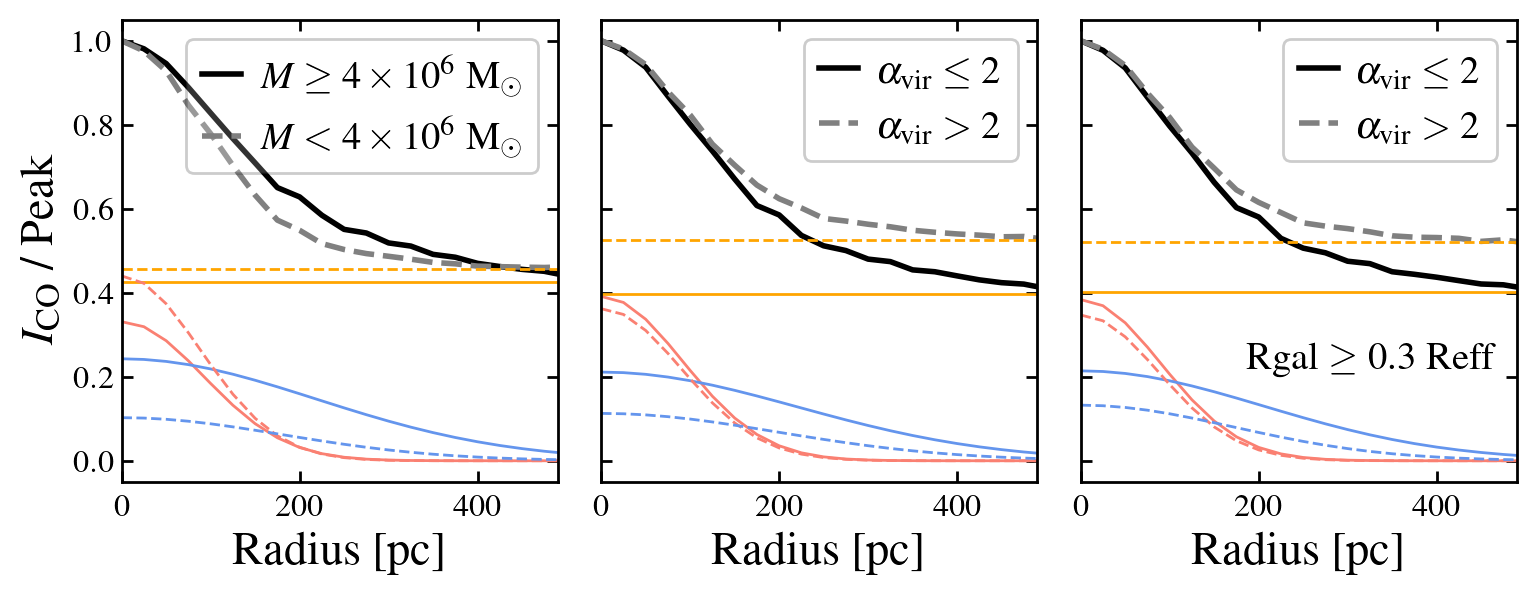

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(9,3), sharey=True, gridspec_kw={'wspace':0.1})
axes = axes.ravel()
ax = axes[0]
ax.set_xlim(0, 490)
ax.set_xlabel('Radius [pc]'); ax.set_ylabel(r"$I_{\mathrm{CO}}$ / Peak")
y_himass_fit, y_himass_comp1, y_himass_comp2, y_himass_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_himass_median[:21])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for massive clouds:', popt, np.sqrt(np.diag(pcov)))
y_lomass_fit, y_lomass_comp1, y_lomass_comp2, y_lomass_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_lomass_median[:21])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for low-mass clouds:', popt, np.sqrt(np.diag(pcov)))
ax.plot(radial_bins[:21], y_himass_median[:21], lw=2, ls='solid', color='black', label=r'$M \geq 4\times10^6$ M$_{\odot}$')
ax.plot(radial_bins[:21], y_lomass_median[:21], lw=2, ls='dashed', color='gray', label=r'$M < 4\times10^6$ M$_{\odot}$')
ax.legend()
ax.plot(radial_bins[:21], y_himass_comp1, lw=1, ls='solid', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_himass_comp2, lw=1, ls='solid', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_himass_comp3, lw=1, ls='solid', color='orange', label='Constant background')
ax.plot(radial_bins[:21], y_lomass_comp1, lw=1, ls='dashed', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_lomass_comp2, lw=1, ls='dashed', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_lomass_comp3, lw=1, ls='dashed', color='orange', label='Constant background')

ax = axes[1]
ax.set_xlim(0, 490)
ax.set_xlabel('Radius [pc]')
y_lovir_fit, y_lovir_comp1, y_lovir_comp2, y_lovir_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_lovir_median[:21])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for bound clouds:', popt, np.sqrt(np.diag(pcov)))
y_hivir_fit, y_hivir_comp1, y_hivir_comp2, y_hivir_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_hivir_median[:21])
err = np.sqrt(np.diag(pcov))
row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for unbound clouds:', popt, np.sqrt(np.diag(pcov)))
ax.plot(radial_bins[:21], y_lovir_median[:21], lw=2, ls='solid', color='black', label=r'$\alpha_{\mathrm{vir}} \leq 2$')
ax.plot(radial_bins[:21], y_hivir_median[:21], lw=2, ls='dashed', color='gray', label=r'$\alpha_{\mathrm{vir}} > 2$')
ax.legend()
ax.plot(radial_bins[:21], y_lovir_comp1, lw=1, ls='solid', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_lovir_comp2, lw=1, ls='solid', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_lovir_comp3, lw=1, ls='solid', color='orange', label='Constant background')
ax.plot(radial_bins[:21], y_hivir_comp1, lw=1, ls='dashed', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_hivir_comp2, lw=1, ls='dashed', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_hivir_comp3, lw=1, ls='dashed', color='orange', label='Constant background')

ax = axes[2]
ax.set_xlim(0, 490)
ax.set_xlabel('Radius [pc]')
ax.annotate(r'Rgal $\geq$ 0.3 Reff', (0.95, 0.3), xycoords='axes fraction', ha='right', va='top')
y_lovir1_fit, y_lovir1_comp1, y_lovir1_comp2, y_lovir1_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_lovir1_median[:21])
err = np.sqrt(np.diag(pcov))
# row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for bound clouds:', popt, np.sqrt(np.diag(pcov)))
y_hivir1_fit, y_hivir1_comp1, y_hivir1_comp2, y_hivir1_comp3, popt, pcov = fit_double_gaus(radial_bins[:21], y_hivir1_median[:21])
err = np.sqrt(np.diag(pcov))
# row_params = np.concatenate((popt, np.array([1-popt[0]-popt[2]]), err, np.sqrt([err[0]**2+err[2]**2]))); fit_params_tab.add_row(row_params)
print('double gaussian parameters for unbound clouds:', popt, np.sqrt(np.diag(pcov)))
ax.plot(radial_bins[:21], y_lovir1_median[:21], lw=2, ls='solid', color='black', label=r'$\alpha_{\mathrm{vir}} \leq 2$')
ax.plot(radial_bins[:21], y_hivir1_median[:21], lw=2, ls='dashed', color='gray', label=r'$\alpha_{\mathrm{vir}} > 2$')
ax.legend()
ax.plot(radial_bins[:21], y_lovir1_comp1, lw=1, ls='solid', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_lovir1_comp2, lw=1, ls='solid', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_lovir1_comp3, lw=1, ls='solid', color='orange', label='Constant background')
ax.plot(radial_bins[:21], y_hivir1_comp1, lw=1, ls='dashed', color='salmon', label='First Gaussian')
ax.plot(radial_bins[:21], y_hivir1_comp2, lw=1, ls='dashed', color='cornflowerblue', label='Second Gaussian')
ax.plot(radial_bins[:21], y_hivir1_comp3, lw=1, ls='dashed', color='orange', label='Constant background')

plt.savefig('../plots/stacked_profile_gmc_propt_test.png', bbox_inches='tight', dpi=300)

Calculate the relative error of the flux fraction from the second components. The function is tricky. The relative error for each flux component is easier to calculate. Then assuming $x=F1/F2$. Then $F2/(F1+F2)$ can be expressed as:
$$f = \frac{1}{1+x}$$
Then the relative error of x can be expressed as:
$$ \sigma_x / x = \sqrt{(\sigma_{F1}/F1)^2+(\sigma{F2}/F2)^2}$$
Assuming $y=1+x$. Then $\sigma_y = \sigma_x$. Then we have
$$\sigma_f / f = \sigma_y / y = \sigma_x / (1+x)$$
Expand this equation using the previous one, we have
$$\sigma_f = f \times \sigma_x / (1+x)$$
Further expand this equation, we have
$$\sigma_f = f \times (\sigma_x/x) \times x/(1+x)$$
$$\sigma_f = f^2 \times (\sigma_x/x) \times F1/F2$$

In [12]:
# add columns that calculates the second Gaussian flux contribution
flux1 = 2*np.pi*fit_params_tab['A1'] * fit_params_tab['sigma1']**2
flux2 = 2*np.pi*fit_params_tab['A2'] * fit_params_tab['sigma2']**2
fit_params_tab['2nd_frac'] = flux2 / (flux1+flux2)
# propogate the error for the fraction
err_flux1_rel = np.sqrt((fit_params_tab['A1_err'] / fit_params_tab['A1'])**2+\
            2*(fit_params_tab['sigma1_err'] / fit_params_tab['sigma2'])**2)
err_flux2_rel = np.sqrt((fit_params_tab['A2_err'] / fit_params_tab['A2'])**2+\
            2*(fit_params_tab['sigma2_err'] / fit_params_tab['sigma2'])**2) 
err_frac = np.sqrt(err_flux1_rel**2+err_flux2_rel**2) * flux1 / flux2 * fit_params_tab['2nd_frac']**2
fit_params_tab['2nd_frac_err'] = err_frac

# # calculate the constant flux level
# flux_C = np.pi*fit_params_tab['C']* 500**2 
# fit_params_tab['C_frac'] = flux_C / (flux_C+flux1+flux2)
# # propagate the error

# keep three significant digits for all columns
if 'region' not in fit_params_tab.colnames:
    for col in fit_params_tab.columns:
        fit_params_tab[col].format = '.2g'

# Add the column of specific regions
if 'region' not in fit_params_tab.colnames:
    regions = ['all data', 'all model', 'high Ico', 'low Ico', 'inner', 'outer',  'arm', 'interarm', 'high mass', 'low mass', 'high vir', 'low vir']
    new_col = Column(data=regions, name='region')
    fit_params_tab.add_column(new_col, index=0)

display(fit_params_tab)

region,A1,sigma1,A2,sigma2,C,A1_err,sigma1_err,A2_err,sigma2_err,C_err,2nd_frac,2nd_frac_err
str9,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32
all data,0.38,90,0.18,2e+02,0.44,0.024,2.4,0.019,18,0.03,0.7,0.037
all model,0.34,94,0.32,1.6e+02,0.34,0.083,6.2,0.08,13,0.12,0.72,0.074
high Ico,0.3,93,0.18,2.1e+02,0.53,0.035,4.4,0.026,30,0.044,0.75,0.053
low Ico,0.43,82,0.22,1.6e+02,0.35,0.04,2.7,0.038,12,0.055,0.65,0.051
inner,0.31,87,0.18,1.8e+02,0.5,0.033,3.7,0.029,18,0.044,0.72,0.048
outer,0.41,90,0.18,2e+02,0.41,0.03,2.7,0.025,19,0.039,0.68,0.046
arm,0.47,85,0.13,2.1e+02,0.39,0.016,1.4,0.012,20,0.021,0.63,0.039
interarm,0.4,83,0.21,1.4e+02,0.39,0.085,4.9,0.084,16,0.12,0.59,0.12
high mass,0.33,92,0.24,2.2e+02,0.43,0.028,3.5,0.02,20,0.035,0.8,0.028


Plot a multipanel of individual galaxies  

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2899136744.py:20: RuntimeWarning: divide by zero encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2899136744.py:20: RuntimeWarning: invalid value encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2899136744.py:54: RuntimeWarning: divide by zero encountered in true_divide
  model2data_ratio = y_mod_elptc /

[3.50931207e-02 2.50000000e+01 3.37620867e-01 1.52381227e+02]


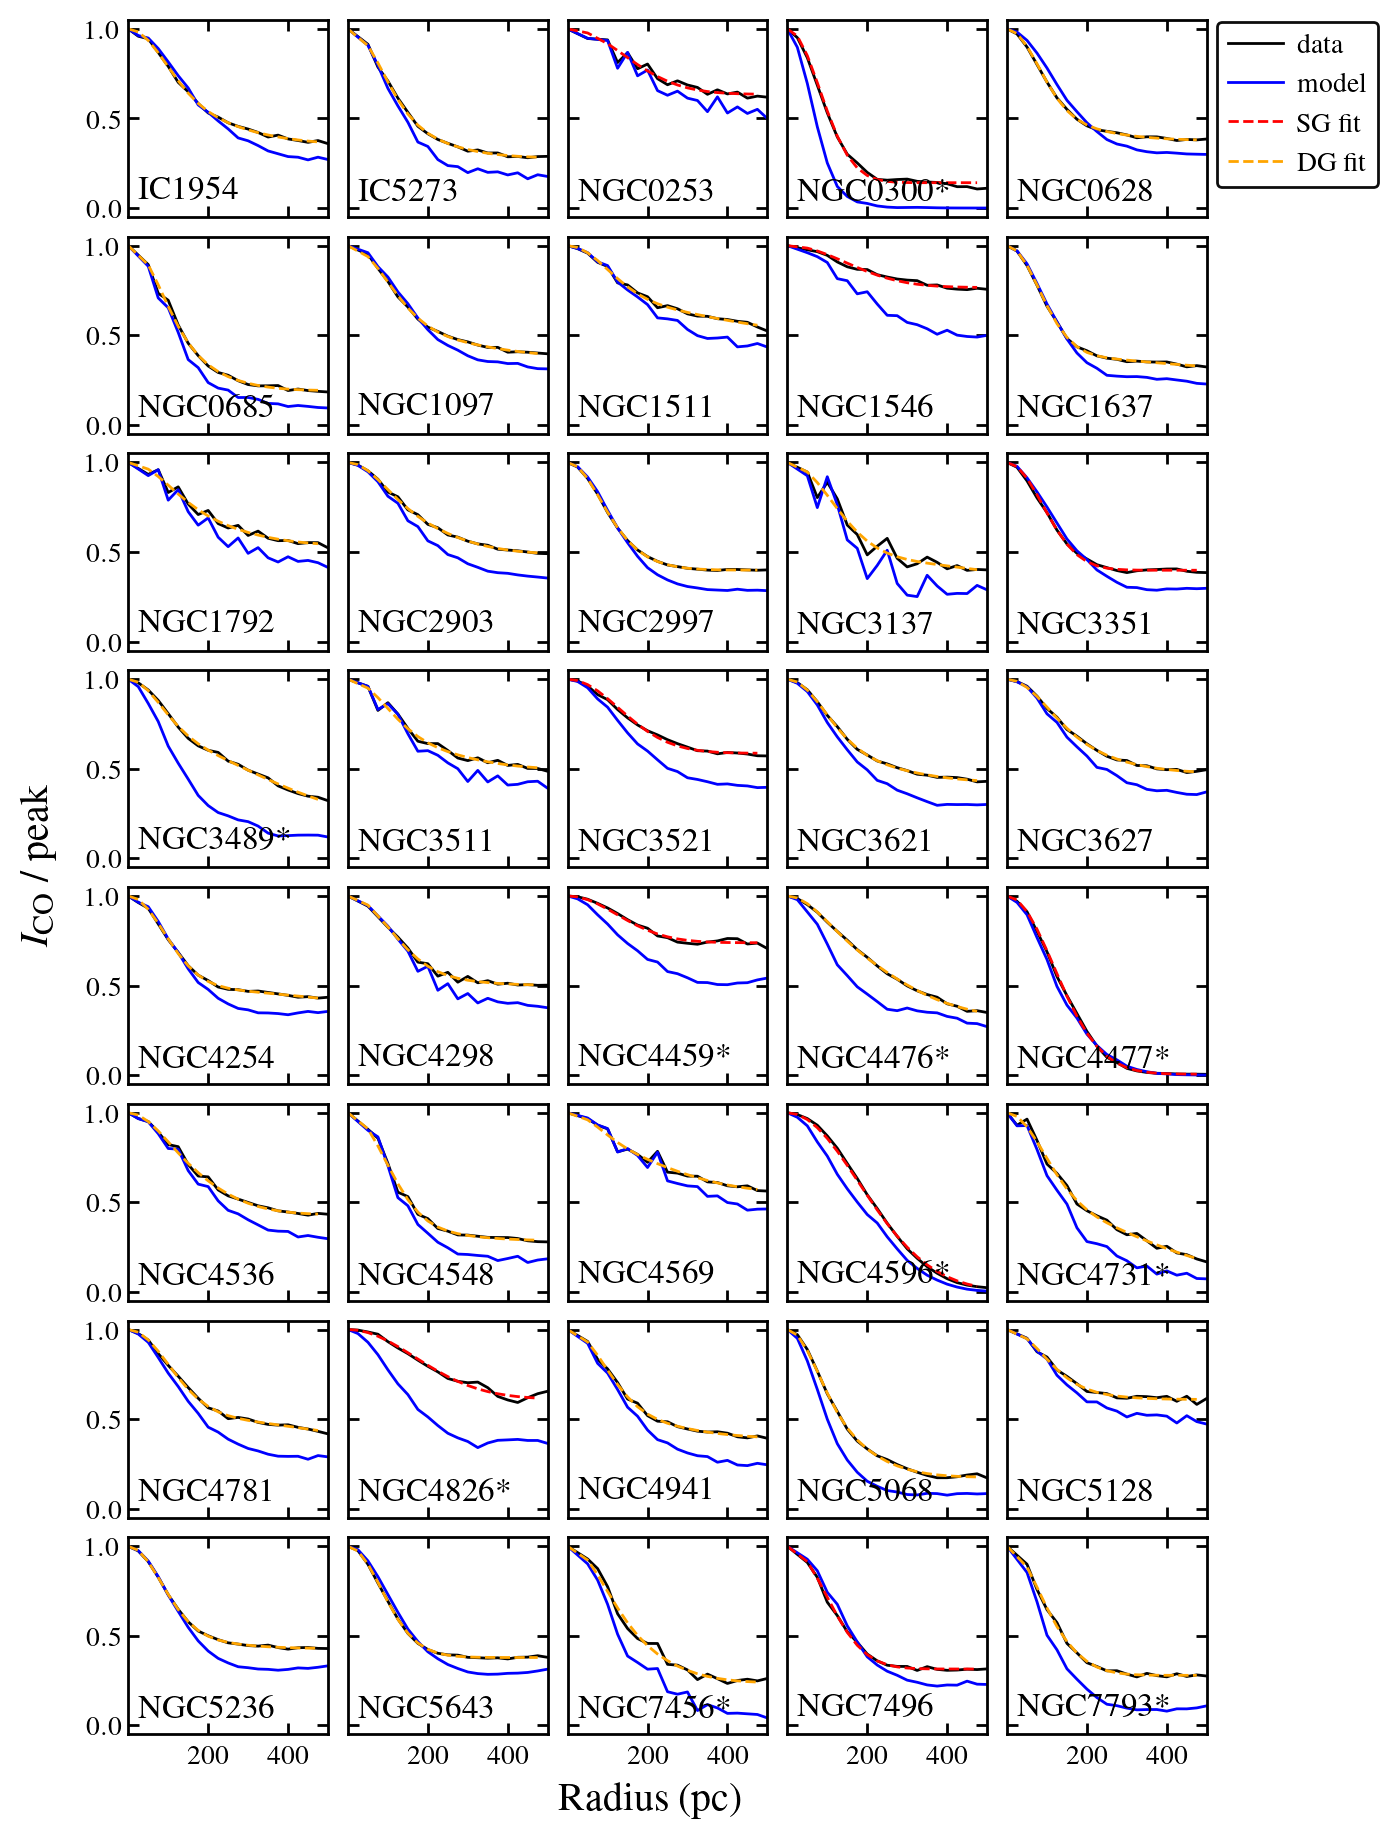

In [18]:
nrow = 8
ncol = 5
mpl_setup('paper-1/1', aspect=8./5., fs=12)
ylabel = r"$I_{\mathrm{CO}}$ / peak" 
xlabel = r"Radius (pc)"

radial_bin = gmc_rad_tabl['radial_bins'][0]

fig, axes = plt.subplots(
    nrow, ncol, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})
axes = axes.ravel()

corr_dict = {}

for i, this_source in enumerate(source_list):
    cloud_rad_profl = Table.read('../cloud_rad_profl_Tmax_vdep/'+this_source+'_150pc_hi_cat.fits')
    
    real = np.array(cloud_rad_profl['radial_real_val'])
    y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
    real_median = np.nanmedian(real, axis=0)
    y_real_median = np.nanmedian(y_real, axis=0)
    bkg_data = np.nanmedian(real[:, 20:40])
    y_bkg_data = np.nanmedian(y_real[:, 20:40])

    # model convolving with a fixed beam size
    model_150pc = np.array(cloud_rad_profl['radial_modelbeam_val'])
    y_mod_150pc = model_150pc / np.repeat(model_150pc[:,0][:, None], 80, axis=1)
    model_150pc_median = np.nanmedian(model_150pc, axis=0)
    y_mod_150pc_median = np.nanmedian(y_mod_150pc, axis=0)
    # model convolving with measured GMC size
    model_gmc_rad = np.array(cloud_rad_profl['radial_model_val'])
    y_mod_gmc_rad = model_gmc_rad / np.repeat(model_gmc_rad[:,0][:, None], 80, axis=1)
    model_gmc_rad_median = np.nanmedian(model_gmc_rad, axis=0)
    y_mod_gmc_rad_median = np.nanmedian(y_mod_gmc_rad, axis=0)
    # model convolving with GMC elliptical beam
    model_elptc = np.array(cloud_rad_profl['radial_model_elptc_val'])
    y_mod_elptc = model_elptc / np.repeat(model_elptc[:,0][:, None], 80, axis=1)
    model_elptc_median = np.nanmedian(model_elptc, axis=0)
    y_mod_elptc_median = np.nanmedian(y_mod_elptc, axis=0)
    bkg_model = np.nanmedian(model_elptc[:, 20:40])
    y_bkg_model = np.nanmedian(y_mod_elptc[:, 20:40])


    # calculate the median of the peak temperature
    cloud_props = Table.read(fid_cat_dict[this_source])
    S2N = np.nanmedian(cloud_props['S2N'])

    # note down the deviation scales
    diff = (y_real_median - y_mod_elptc_median) / y_real_median
    diff_scale = radial_bin[np.where(diff>0.1)[0][0]]

    # GMC flux fraction 
    model2data_ratio = y_mod_elptc / y_real
    model2data_ratio_med = np.nanmedian(model2data_ratio, axis=0)

    # add stellar mass
    prop_this_source = sample_tab[sample_tab['name']==this_source]
    Mstar = prop_this_source['props_mstar'][0]
    Mmol = prop_this_source['mh2_phangs'][0]


    corr_dict[this_source] = {
        'galaxy': this_source.upper(), 
        'mstar': Mstar, 
        'Mmol': Mmol, 
        'S2N': S2N, 
        'data_median': real_median,
        'data_median_norm': y_real_median,
        'peak_data': real_median[0],  
        'model_150pc_median': model_150pc_median,
        'model_150pc_median_norm': y_mod_150pc_median,
        'model_gmc_median': model_gmc_rad_median,
        'model_gmc_median_norm': y_mod_gmc_rad_median,
        'model_elptc_median': model_elptc_median,
        'model_elptc_median_norm': y_mod_elptc_median,
        'model2data_ratio': model2data_ratio_med, 
        'bkg_data': y_bkg_data, 
        'bkg_model': y_bkg_model, 
        'bkg_ratio': y_bkg_model / y_bkg_data,
        'diff_scale': diff_scale
    }

    ax = axes[i]
    # ax.set_yscale('log')
    # plot the real radial profile
    radial_bin = cloud_rad_profl['radial_bins'][0]
    condition = ~np.isnan(real_median)
    ax.plot(radial_bin[condition], y_real_median[condition], color='black')
    # plot the model median with fixed beam
    # ax.plot(radial_bin[condition], y_mod_150pc_median[condition], color='red', label='model, 150 pc beam', lw=1)
    # # plot the model median convolved with GMC size
    # ax.plot(radial_bin[condition], y_mod_gmc_rad_median[condition], color='green', label='model, circular GMC', lw=1, ls='dashed')
    # plot the model convolved with elliptical GMC size
    ax.plot(radial_bin[condition], y_mod_elptc_median[condition], color='blue')
    ax.set_xlim(0, 500)
    # annotate the galaxy name
    if this_source in source_nthresh:
        source_name = this_source.upper()+'*'
    else:
        source_name = this_source.upper()
    ax.annotate(source_name, (0.05, 0.05), ha='left', va='bottom', xycoords='axes fraction')
    # fit either single Gaussian or double Gaussian to the radial profile 
    condition = ~np.isnan(y_real_median[:20])
    x = radial_bin[:20][condition]; y = y_real_median[:20][condition]
    y_fit1, _, _,  popt1, _ = fit_single_gaus(x, y, p0=[0.8, 150])
    rms1 = np.sqrt(np.mean((y-y_fit1)**2))
    # try the double Gaussian and compare with single Gaussian results. 
    try:
        y_fit2, _, _, _, popt2, _ = fit_double_gaus(x, y, p0=[0.3, 90, 0.2, 200])
        rms2 = np.sqrt(np.mean((y-y_fit2)**2))
        # if (rms1 < rms2) | (popt2[1] < 0) | (popt2[3] < 0) | (popt2[0] < 0.1) | (popt2[2]<0.1):
        if (rms1 < rms2)  | (popt2[0]*popt2[1]**2/popt2[2]/popt2[3]**2 > 10) | (1-popt2[0]-popt2[2]<0) | (popt2[0]< 0.1): # | (popt2[3]>1000)  |  :
            y_fit = y_fit1
            corr_dict[this_source]['fit_type'] = 'single'
            popt = popt1; popt[0] = np.round(popt[0], 2); popt[1] = round(popt[1])
            corr_dict[this_source]['fit_params'] = list(popt)+[round(1-popt[0],2)]
        else:
            y_fit = y_fit2
            corr_dict[this_source]['fit_type'] = 'double'
            popt = popt2; popt[0] = np.round(popt[0], 2); popt[2] = np.round(popt[2], 2); popt[1] = round(popt[1]); popt[3] = round(popt[3])
            corr_dict[this_source]['fit_params'] = list(popt)+[round(1-popt[0]-popt[2],2)]
    except:
        y_fit = y_fit1
        corr_dict[this_source]['fit_type'] = 'single'
        popt = popt1; popt[0] = np.round(popt[0], 2); popt[1] = round(popt[1])
        corr_dict[this_source]['fit_params'] = list(popt)+[round(1-popt[0],2)]
    condition = ~np.isnan(y_fit)
    if corr_dict[this_source]['fit_type'] == 'single':
        color = 'red'
    else:
        color= 'orange'
    ax.plot(x, y_fit, color=color, ls='dashed')
    # set the number of ticks
    ax.set_xticks([200, 400])
    if this_source == 'ngc0253':
        popt2_check = popt2

    # if i==0:
    #     ax.legend(fontsize=7)
    # # plot the legend
    if i == 4:
        ax.plot([], [], color='black', lw=1, label='data')
        ax.plot([], [], color='blue', lw=1, label='model')
        ax.plot([], [], color='red', ls='dashed', label='SG fit')
        ax.plot([], [], color='orange', ls='dashed', label='DG fit')
        ax.legend(fancybox=True, framealpha=0.95, loc = (1.05, 0.15), #loc=(1.0,1.0), #loc='upper right', 
            ncol=1, fontsize=10, handlelength=2)  

# axes[34].remove()
fig.text(0.06, 0.5, ylabel, va='center', ha='center', rotation='vertical', fontsize='large')
fig.text(0.5, 0.08, xlabel, va='center', ha='center', rotation='horizontal', fontsize='large')
plt.savefig('../plots/radial_profile_indvdl_galaxy.png', bbox_inches='tight', dpi=300)

print(popt2_check)

Put the results into a table

In [28]:
import pickle
stats_tab = Table()
columns_selct = ['galaxy', 'peak_data', 'bkg_data', 'bkg_model', 'bkg_ratio', 'diff_scale', 'mstar', 'Mmol', 'S2N', 'fit_type']
fit_params_2d = []

for i, source in enumerate(source_list):
    corr_dict_sub = {k:[corr_dict[source][k]] for k in columns_selct}
    tab_temp = Table(corr_dict_sub)
    stats_tab = vstack([stats_tab, tab_temp])
    fit_params_2d.append(corr_dict[source]['fit_params'])

stats_tab = stats_tab[columns_selct]
stats_tab['fit_params'] = np.array(fit_params_2d, dtype='object')
columns_selct.remove('galaxy'); columns_selct.remove('fit_type')

for column in columns_selct:
    stats_tab[column] = np.round(stats_tab[column], 2)
stats_tab['peak_data'] = np.round(stats_tab['peak_data'], 1)
stats_tab['diff_scale'] = stats_tab['diff_scale'].astype(int)

# customize the fit params column
for i, row in enumerate(stats_tab['fit_params']):
    formatted = [str(int(x)) if isinstance(x, float) and x.is_integer() else str(x) for x in row]
    stats_tab['fit_params'][i] = f"[{', '.join(formatted)}]"

# import the flux fraction from Annie's catalog
flux_tab = Table.read('../PHANGS_gmcfluxstats_150pc_46mK_fovall_s2n4.fits')
print(flux_tab.columns)
flux_tab['GAL_NAME'][0] = flux_tab['GAL_NAME'][0].replace(" ", ""); flux_tab['GAL_NAME'][1] = flux_tab['GAL_NAME'][1].replace(" ", "")
flux_tab['GAL_NAME'] = np.char.upper(flux_tab['GAL_NAME'])
flux_tab_selct = flux_tab[['GAL_NAME', 'LCO_GMCS', 'LCO_CUBE','LCO_NOEX_GMCS', 'GAL_LOGMSTAR']]
flux_tab_selct['gmc_frac'] = np.round(flux_tab_selct['LCO_GMCS'] / flux_tab_selct['LCO_CUBE'], 2)
stats_tab = join(stats_tab, flux_tab_selct[['GAL_NAME','gmc_frac']], join_type='left', keys_left='galaxy', keys_right='GAL_NAME')

# read the flux fraction from the model / data. 
with open('../tables/galaxy_fluxes_vdep.pkl', 'rb') as fp:
    galaxy_fluxes = pickle.load(fp)
stats_tab['flux_ratio'] = np.round(galaxy_fluxes['ratio'],2)
stats_tab["galaxy"] = stats_tab["galaxy"].astype("<U8")

col_print = ['galaxy', 'peak_data', 'bkg_data', 'bkg_model', 'bkg_ratio', 'flux_ratio', 'gmc_frac', 'diff_scale', 'fit_type', 'fit_params']
stats_tab_print = stats_tab[col_print]

for this_source in source_nthresh:
    idx = np.where(stats_tab_print['galaxy']==this_source.upper())
    stats_tab_print['galaxy'][idx] = this_source.upper()+'*'

latex_code = stats_tab_print.write(filename='../tables/table_stacking_summary.tex', format='latex', overwrite=True)

col = ['galaxy', 'peak_data', 'bkg_data', 'bkg_model', 'bkg_ratio', 'flux_ratio', 'gmc_frac', 'diff_scale']
stats_tab_save = stats_tab[col]
stats_tab_save.write('../tables/stacking_table.fits', format='fits', overwrite=True)

# stats_tab.sort('gmc_frac')
display(stats_tab_print)
# stats_tab.write('../tables/stacking_table.fits', format='fits', overwrite=True)

<TableColumns names=('GAL_NAME','RESO','SENS','SN_THRESH','MED_FIELD_RELRAD','P75_FIELD_RELRAD','P25_FIELD_RELRAD','P84_FIELD_RELRAD','P16_FIELD_RELRAD','MED_FIELD_RELRAD_ALL','P75_FIELD_RELRAD_ALL','P25_FIELD_RELRAD_ALL','P84_FIELD_RELRAD_ALL','P16_FIELD_RELRAD_ALL','LCO_CUBE','LCO_MAP','LCO_FOV_MAP','LCO_COMPLETE_MAP','LCO_MAP_ARM','LCO_FOV_MAP_ARM','LCO_COMPLETE_MAP_ARM','LCO_MAP_IARM','LCO_FOV_MAP_IARM','LCO_COMPLETE_MAP_IARM','LCO_MAP_DISK','LCO_FOV_MAP_DISK','LCO_COMPLETE_MAP_DISK','LCO_SCUBE','LCO_SMAP','LCO_FOV_SMAP','LCO_COMPLETE_SMAP','LCO_SMAP_ARM','LCO_FOV_SMAP_ARM','LCO_COMPLETE_SMAP_ARM','LCO_SMAP_IARM','LCO_FOV_SMAP_IARM','LCO_COMPLETE_SMAP_IARM','LCO_SMAP_DISK','LCO_FOV_SMAP_DISK','LCO_COMPLETE_SMAP_DISK','LCO_ACUBE','LCO_AMAP','LCO_FOV_AMAP','LCO_COMPLETE_AMAP','LCO_AMAP_ARM','LCO_FOV_AMAP_ARM','LCO_COMPLETE_AMAP_ARM','LCO_AMAP_IARM','LCO_FOV_AMAP_IARM','LCO_COMPLETE_AMAP_IARM','LCO_AMAP_DISK','LCO_FOV_AMAP_DISK','LCO_COMPLETE_AMAP_DISK','GAL_INCL','GAL_DIST','GAL_FOV_

galaxy,peak_data,bkg_data,bkg_model,bkg_ratio,flux_ratio,gmc_frac,diff_scale,fit_type,fit_params
str8,float64,float64,float64,float64,float64,float32,int64,str6,object
IC1954,6.1,0.39,0.3,0.79,0.72,0.73,275,double,"[0.39, 90, 0.25, 198, 0.36]"
IC5273,3.8,0.27,0.18,0.66,0.69,0.48,150,double,"[0.49, 82, 0.23, 168, 0.28]"
NGC0253,12.4,0.58,0.48,0.84,1.08,0.92,300,single,"[0.37, 139, 0.63]"
NGC0300*,2.1,0.12,0.0,0.0,0.14,0.01,50,single,"[0.86, 81, 0.14]"
NGC0628,5.7,0.38,0.31,0.82,0.86,0.83,250,double,"[0.49, 77, 0.14, 171, 0.37]"
NGC0685,2.9,0.18,0.1,0.56,0.63,0.4,150,double,"[0.51, 80, 0.3, 151, 0.19]"
NGC1097,7.1,0.36,0.27,0.76,0.86,0.88,250,double,"[0.44, 95, 0.19, 233, 0.37]"
NGC1511,12.3,0.49,0.41,0.82,0.77,0.93,250,double,"[0.29, 96, 0.22, 299, 0.49]"
NGC1546,24.8,0.77,0.48,0.62,0.56,0.95,125,single,"[0.23, 144, 0.77]"


Put all galaxies in one plot

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2233929578.py:3: RuntimeWarning: divide by zero encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2233929578.py:3: RuntimeWarning: invalid value encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2233929578.py:22: RuntimeWarning: divide by zero encountered in true_divide
  f_gmc_arr = y_mod_elptc / y_real
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4650: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  arr.partition(


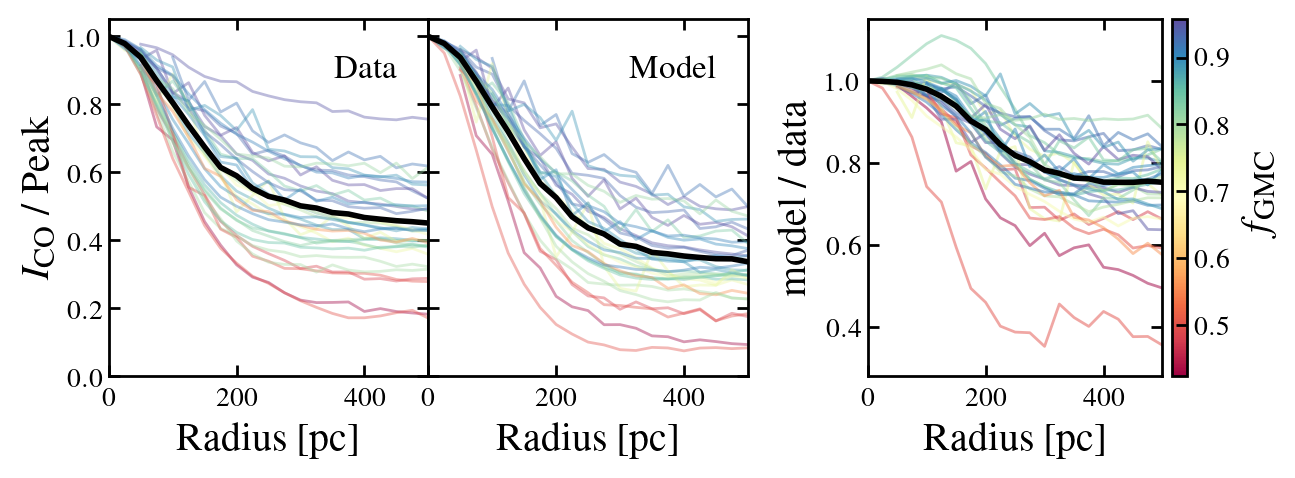

In [29]:
# data profile
real = np.array(gmc_stacked['radial_real_val'])
y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
real_median = np.nanmedian(real, axis=0)
y_real_median = np.nanmedian(y_real, axis=0)
# model convolving with a fixed beam size
model_150pc = np.array(gmc_stacked['radial_modelbeam_val'])
y_mod_150pc = model_150pc / np.repeat(model_150pc[:,0][:, None], 80, axis=1)
model_150pc_median = np.nanmedian(model_150pc, axis=0)
y_mod_150pc_median = np.nanmedian(y_mod_150pc, axis=0)
# model convolving with measured GMC size
model_gmc_rad = np.array(gmc_stacked['radial_model_val'])
y_mod_gmc_rad = model_gmc_rad / np.repeat(model_gmc_rad[:,0][:, None], 80, axis=1)
model_gmc_rad_median = np.nanmedian(model_gmc_rad, axis=0)
y_mod_gmc_rad_median = np.nanmedian(y_mod_gmc_rad, axis=0)
# model convolving with GMC elliptical beam
model_elptc = np.array(gmc_stacked['radial_model_elptc_val'])
y_mod_elptc = model_elptc / np.repeat(model_elptc[:,0][:, None], 80, axis=1)
model_elptc_median = np.nanmedian(model_elptc, axis=0)
y_mod_elptc_median = np.nanmedian(y_mod_elptc, axis=0)

f_gmc_arr = y_mod_elptc / y_real

f_gmc_16th = np.nanpercentile(f_gmc_arr, 16, axis=0)
f_gmc_med = np.nanpercentile(f_gmc_arr, 50, axis=0)
f_gmc_84th = np.nanpercentile(f_gmc_arr, 84, axis=0)
f_gmc_err_lo = (f_gmc_med - f_gmc_16th) / np.shape(f_gmc_arr)[1]
f_gmc_err_hi = (f_gmc_84th - f_gmc_med) / np.shape(f_gmc_arr)[1]


source_bin = [source for source in source_list if source not in source_nthresh]
_, idx, _ = np.intersect1d(np.array(source_list), np.array(source_bin), return_indices=True)

mpl_setup('paper-1/1', aspect=3./9., fs=12)
# fig, axes = plt.subplots(nrows=1, ncols=3, gridspec_kw={'wspace': 0.25})
# axes = axes.ravel()

fig = plt.figure()
outer = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.25)
left = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[0], wspace=0.0)

import matplotlib.cm as cm
cmap = cm.coolwarm  # You can choose any colormap
cmap = cm.Spectral
stats_tab_selc = stats_tab[np.isin(stats_tab['galaxy'], np.char.upper(source_bin))]
norm = mpl.colors.Normalize(vmin=np.nanpercentile(np.log10(stats_tab_selc['peak_data']), 1), 
                            vmax=np.nanpercentile(np.log10(stats_tab_selc['peak_data']), 99))  # Normalize the quantities
# Normalize by the flux fraction
norm = mpl.colors.Normalize(vmin=np.nanpercentile(stats_tab_selc['gmc_frac'], 1), 
                            vmax=np.nanpercentile(stats_tab_selc['gmc_frac'], 99))  # Normalize the quantities

ax = fig.add_subplot(left[0, 0])
ax.set_xlim(0, 500); ax.set_ylim(0.0, 1.05)
for i, this_source in enumerate(source_bin):
    ax.plot(gmc_stacked['radial_bins'][0], corr_dict[this_source]['data_median_norm'],  alpha=0.4, color=cmap(norm(stats_tab_selc['gmc_frac'][i]))) # color='salmon',
    # ax.plot(gmc_stacked['radial_bins'][0], corr_dict[this_source]['model_elptc_median_norm'], color='dodgerblue', alpha=0.4)

ax.plot(gmc_stacked['radial_bins'][0], y_real_median, color='black', lw=2)
# ax.plot(gmc_stacked['radial_bins'][0], y_mod_elptc_median, color='blue', lw=2, label='model')
ax.set_xlabel('Radius [pc]'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ / Peak')
ax.annotate('Data', (0.9, 0.9), xycoords='axes fraction', ha='right', va='top')

ax1 = fig.add_subplot(left[0, 1], sharey=ax)
plt.setp(ax1.get_yticklabels(), visible=False)
ax1.set_xlim(0, 500); ax1.set_ylim(0.0, 1.05)
for i, this_source in enumerate(source_bin):
    # ax.plot(gmc_stacked['radial_bins'][0], corr_dict[this_source]['data_median_norm'],  alpha=0.4, color=cmap(norm(stats_tab_selc['gmc_frac'][i]))) # color='salmon',
    ax1.plot(gmc_stacked['radial_bins'][0], corr_dict[this_source]['model_elptc_median_norm'],  alpha=0.4, color=cmap(norm(stats_tab_selc['gmc_frac'][i]))) # color='dodgerblue',

# ax.plot(gmc_stacked['radial_bins'][0], y_real_median, color='black', lw=2)
ax1.plot(gmc_stacked['radial_bins'][0], y_mod_elptc_median, color='black', lw=2, label='model')
ax1.set_xlabel('Radius [pc]')
ax1.annotate('Model', (0.9, 0.9), xycoords='axes fraction', ha='right', va='top')


# # Plot lines
# plt.figure(figsize=(8, 6))
# for i, q in enumerate(quantities):
#     y = np.sin(x + i * 0.5)  # Example line data
#     plt.plot(x, y, color=cmap(norm(q)), label=f'Quantity: {q:.2f}')

ax = fig.add_subplot(outer[1])
ax.set_xlabel('Radius [pc]'); ax.set_ylabel(r'model / data')
ax.set_xlim(0, 500)
for i, this_source in enumerate(source_bin):
    f_gmc = corr_dict[this_source]['model2data_ratio']
    # ax.plot(gmc_stacked['radial_bins'][0], f_gmc, color='gray', alpha=0.4)
    ax.plot(gmc_stacked['radial_bins'][0], f_gmc, color=cmap(norm(stats_tab_selc['gmc_frac'][i])), alpha=0.5)
ax.plot(gmc_stacked['radial_bins'][0], f_gmc_med, color='black', lw=2, zorder=5)
# ax.fill_between(gmc_stacked['radial_bins'][0],(f_gmc_16th),(f_gmc_84th),
#                     color='salmon',zorder=3,alpha=0.4, label=r'16-84\% range')
# ax.fill_between(gmc_stacked['radial_bins'][0],(f_gmc_med-f_gmc_err_lo),(f_gmc_med+f_gmc_err_hi),
#                     color='cornflowerblue',zorder=4,alpha=0.65, label=r'Unc. on med.')
# ax.legend()
# plot the color bar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.05)
cbar = plt.colorbar(sm, cax=cax, orientation='vertical')
# cax.set_ylabel(r'$\log_{10}$(Peak) (K km s$^{-1}$)')
cax.set_ylabel(r'$f_{\mathrm{GMC}}$')
plt.savefig('../plots/GMC_flux_fraction_3panel.png', bbox_inches='tight', dpi=300)

Try correlate the offset with the GMC flux fraction

<TableColumns names=('GAL_NAME','RESO','SENS','SN_THRESH','MED_FIELD_RELRAD','P75_FIELD_RELRAD','P25_FIELD_RELRAD','P84_FIELD_RELRAD','P16_FIELD_RELRAD','MED_FIELD_RELRAD_ALL','P75_FIELD_RELRAD_ALL','P25_FIELD_RELRAD_ALL','P84_FIELD_RELRAD_ALL','P16_FIELD_RELRAD_ALL','LCO_CUBE','LCO_MAP','LCO_FOV_MAP','LCO_COMPLETE_MAP','LCO_MAP_ARM','LCO_FOV_MAP_ARM','LCO_COMPLETE_MAP_ARM','LCO_MAP_IARM','LCO_FOV_MAP_IARM','LCO_COMPLETE_MAP_IARM','LCO_MAP_DISK','LCO_FOV_MAP_DISK','LCO_COMPLETE_MAP_DISK','LCO_SCUBE','LCO_SMAP','LCO_FOV_SMAP','LCO_COMPLETE_SMAP','LCO_SMAP_ARM','LCO_FOV_SMAP_ARM','LCO_COMPLETE_SMAP_ARM','LCO_SMAP_IARM','LCO_FOV_SMAP_IARM','LCO_COMPLETE_SMAP_IARM','LCO_SMAP_DISK','LCO_FOV_SMAP_DISK','LCO_COMPLETE_SMAP_DISK','LCO_ACUBE','LCO_AMAP','LCO_FOV_AMAP','LCO_COMPLETE_AMAP','LCO_AMAP_ARM','LCO_FOV_AMAP_ARM','LCO_COMPLETE_AMAP_ARM','LCO_AMAP_IARM','LCO_FOV_AMAP_IARM','LCO_COMPLETE_AMAP_IARM','LCO_AMAP_DISK','LCO_FOV_AMAP_DISK','LCO_COMPLETE_AMAP_DISK','GAL_INCL','GAL_DIST','GAL_FOV_

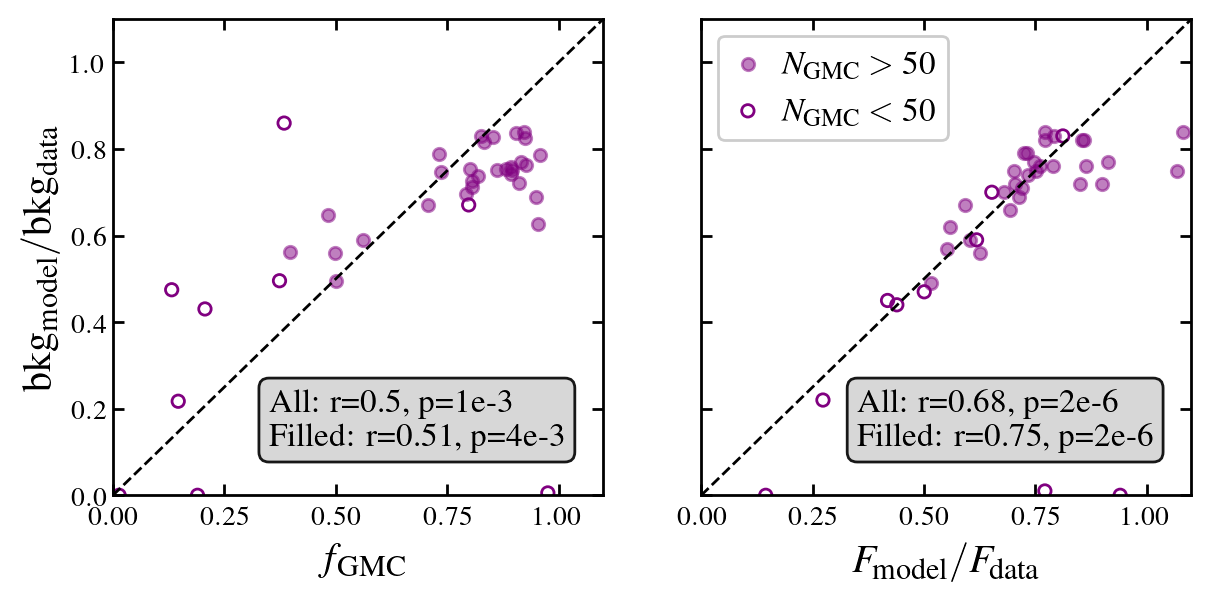

In [34]:
# import the flux fraction from Annie's catalog
flux_tab = Table.read('../PHANGS_gmcfluxstats_150pc_46mK_fovall_s2n4.fits')
print(flux_tab.columns)
flux_tab['GAL_NAME'][0] = flux_tab['GAL_NAME'][0].replace(" ", ""); flux_tab['GAL_NAME'][1] = flux_tab['GAL_NAME'][1].replace(" ", "")

flux_tab_selct = flux_tab[['GAL_NAME', 'LCO_GMCS', 'LCO_MAP', 'LCO_CUBE','LCO_NOEX_GMCS', 'GAL_LOGMSTAR']]
flux_tab_selct['flux_frac'] = flux_tab_selct['LCO_GMCS'] / flux_tab_selct['LCO_CUBE']
flux_tab_selct['rad_offset'] = np.full(np.shape(flux_tab_selct['flux_frac']), fill_value=np.nan)

# import the flux fraction directly calculated from the ratio of model map and data map
import pickle
# read the flux fraction from the model / data. 
with open('../tables/galaxy_fluxes_vdep.pkl', 'rb') as fp:
    galaxy_fluxes = pickle.load(fp)

source_nthresh = ['ngc0300','ngc3489','ngc4459', 'ngc4476', 'ngc4477', 'ngc4596', 'ngc4731', 'ngc4826', 'ngc7456', 'ngc7793']

for i, this_source in enumerate(source_list):
    f_gmc_avg = np.nanmedian(corr_dict[this_source]['model_elptc_median_norm'][20:40]) / np.nanmedian(corr_dict[this_source]['data_median_norm'][20:40])
    # if this_source in source_nthresh:
    #     this_source = this_source+'*'
    # f_gmc_avg = stats_tab['gmc_frac'][stats_tab['galaxy']==this_source]
    idx = np.where(flux_tab_selct['GAL_NAME']==this_source)
    flux_tab_selct['rad_offset'][idx] = f_gmc_avg
mask = np.isnan(flux_tab_selct['rad_offset'])
flux_tab_selct = flux_tab_selct[~mask]
source_nthresh = ['ngc0300','ngc3489','ngc4459', 'ngc4476', 'ngc4477', 'ngc4596', 'ngc4731', 'ngc4826', 'ngc7456', 'ngc7793']
_, idx, _ = np.intersect1d(flux_tab_selct['GAL_NAME'], source_nthresh, return_indices=True)
mask = np.ones(np.shape(flux_tab_selct['GAL_NAME']), bool)
mask[idx] = False

mpl_setup('paper-1/1', aspect=4./9., fs=12)
fig, axes = plt.subplots(1, 2, sharey='all')
axes = axes.ravel()
ax = axes[0]
# ax.set_xscale('log'); ax.set_yscale('log')
ax.scatter(flux_tab_selct['flux_frac'][mask], flux_tab_selct['rad_offset'][mask], marker='o', s=20, color='purple', alpha=0.5, label=r'$N_{\mathrm{GMC}}>50$')
ax.scatter(flux_tab_selct['flux_frac'][~mask], flux_tab_selct['rad_offset'][~mask], marker='o', s=20, facecolor='None', edgecolor='purple', label=r'$N_{\mathrm{GMC}}<50$')
ax.set_xlim(0,1.1); ax.set_ylim(0,1.1)
# ax.legend(loc='upper left', fontsize=10)
# ax.xaxis.set_minor_locator(plt.MaxNLocator(1)); ax.yaxis.set_minor_locator(plt.MaxNLocator(1))
ax.plot([0,10], [0,10], ls='dashed', color='black')
# calculate the rank coefficient 
from scipy.stats import pearsonr, spearmanr
corr_value, p_value = spearmanr(flux_tab_selct['flux_frac'], flux_tab_selct['rad_offset'])
print(corr_value, p_value)
corr_value2, p_value2 = spearmanr(flux_tab_selct['flux_frac'][mask], flux_tab_selct['rad_offset'][mask])
print(corr_value2, p_value2)
bbox_props = dict(boxstyle="round", fc="lightgray", ec='black',alpha=0.9)
ax.annotate('All: r=0.5, p=1e-3 \n Filled: r=0.51, p=4e-3', (0.35, 0.1), va='bottom', ha='left', bbox=bbox_props)
# ax.annotate('Filled: r=0.52, p=3e-3', (0.7, 0.2), va='top', ha='center')
# ax.annotate()

ax.set_ylabel(r'$\mathrm{bkg_{model}} / \mathrm{bkg_{data}}$'); ax.set_xlabel(r'$f_{\mathrm{GMC}}$')

ax = axes[1]
ax.set_xlabel(r'$F_{\mathrm{model}}/F_{\mathrm{data}}$')
ax.set_xlim(0,1.1)
ax.plot([0,10],[0,10],ls='dashed', color='black')
mask = np.isin(stats_tab['galaxy'], np.char.upper(source_bin))
plt.scatter(np.array(galaxy_fluxes['ratio'])[mask], stats_tab['bkg_ratio'][mask], marker='o', s=20, color='purple', alpha=0.5, label=r'$N_{\mathrm{GMC}}>50$')
plt.scatter(np.array(galaxy_fluxes['ratio'])[~mask], stats_tab['bkg_ratio'][~mask], marker='o', s=20, color='purple', facecolor='None', edgecolor='purple',
            label=r'$N_{\mathrm{GMC}}<50$')
# plot the legend
ax.legend(loc='upper left')
corr_value, p_value = spearmanr(np.array(galaxy_fluxes['ratio']), stats_tab['bkg_ratio'])
print(corr_value, p_value)
corr_value2, p_value2 = spearmanr(np.array(galaxy_fluxes['ratio'])[mask], stats_tab['bkg_ratio'][mask])
print(corr_value2, p_value2)
bbox_props = dict(boxstyle="round", fc="lightgray", ec='black',alpha=0.9)
ax.annotate('All: r=0.68, p=2e-6 \n Filled: r=0.75, p=2e-6', (0.35, 0.1), va='bottom', ha='left', bbox=bbox_props)

plt.savefig('../plots/flux_fraction_cross_check.png', bbox_inches='tight', dpi=300)

# fig = plt.figure(figsize=(3,3))
# plt.scatter(flux_tab_selct['GAL_LOGMSTAR'][mask], flux_tab_selct['rad_offset'][mask], marker='o', s=20, color='purple', alpha=0.5)

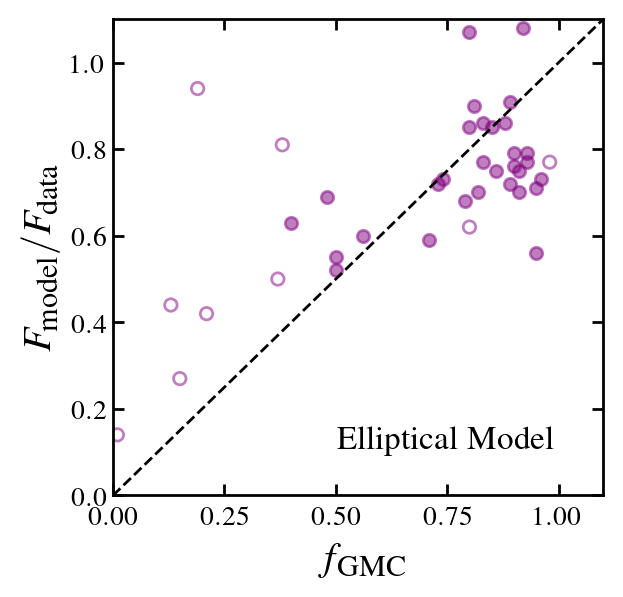

In [35]:
mpl_setup('paper-1/1', aspect=4./9., fs=12)
fig = plt.figure()
ax = plt.subplot(121)
ax.set_xlim(0,1.1); ax.set_ylim(0,1.1)
ax.set_xlabel(r'$f_{\mathrm{GMC}}$'); ax.set_ylabel(r'$F_{\mathrm{model}}/F_{\mathrm{data}}$')
mask = np.isin(stats_tab['galaxy'], np.char.upper(source_bin))
plt.scatter(stats_tab['gmc_frac'][mask], stats_tab['flux_ratio'][mask], color='purple', marker='o', alpha=0.5, s=20)
plt.scatter(stats_tab['gmc_frac'][~mask], stats_tab['flux_ratio'][~mask], facecolor='None', edgecolor='purple', marker='o', alpha=0.5, s=20)
plt.plot([0,2], [0,2], ls='dashed', color='black')
ax.annotate('Elliptical Model', (0.9, 0.1), xycoords='axes fraction', ha='right')

plt.savefig('../plots/Model_GMC_flux_comprs.png', bbox_inches='tight')

## Further Analyses

In [36]:
gmc_stacked = Table()
for i, this_source in enumerate(source_list):
    # infile_name = '../cloud_radial_profile/'+this_source+'_150pc_hi_cat.fits'
    infile_name = '../cloud_rad_profl_Tmax_vdep/'+this_source+'_150pc_hi_cat.fits'
    gmc_rad_tabl = Table.read(infile_name)
    gmc_stacked = vstack([gmc_stacked, gmc_rad_tabl])

#### Compare the stacked profiles at different resolutions

sigma for the first Gaussian component: 38.31667153559879 88.03095600286616
sigma for the second Gaussian component:  145.57653194464183 189.28128518960003


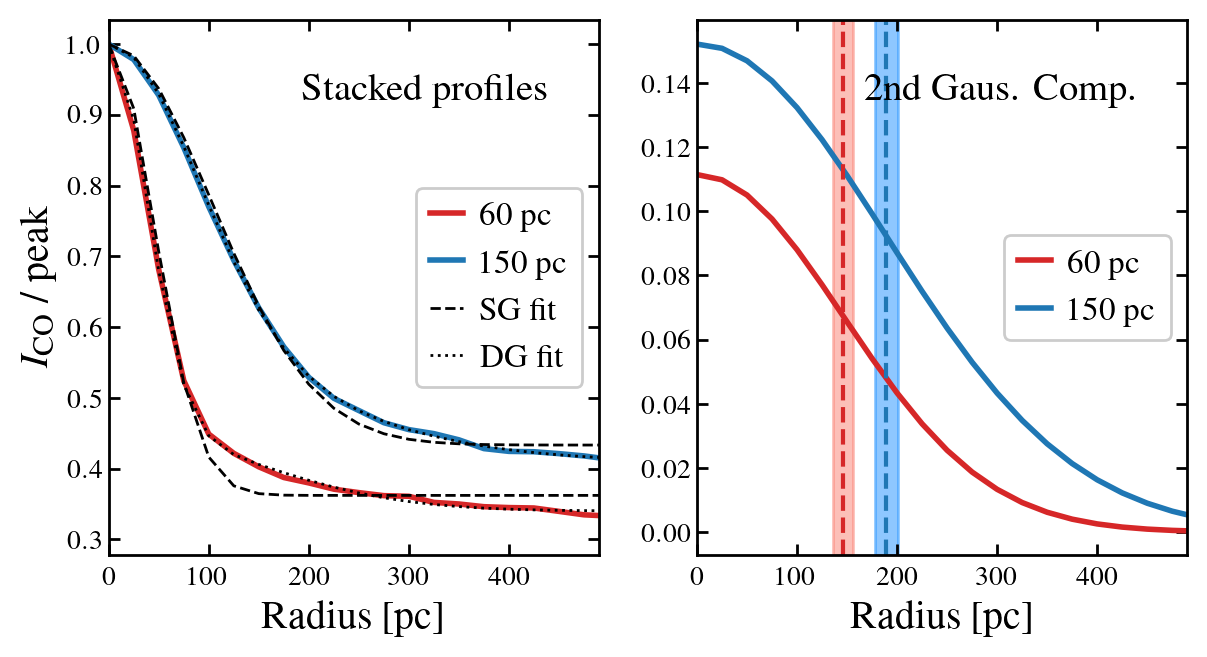

In [38]:
%matplotlib inline
corr_dict = {}
source_60pc_list = get_source_list('../cloud_rad_profl_60pc_Tmax_vdep')

# calculate the median of stacked profile
gmc_60pc_stacked = Table()
for i, this_source in enumerate(source_60pc_list):
    infile_name = '../cloud_rad_profl_60pc_Tmax_vdep/'+this_source+'_60pc_hi_cat.fits'
    gmc_rad_tabl = Table.read(infile_name)
    gmc_60pc_stacked = vstack([gmc_60pc_stacked, gmc_rad_tabl])
    
gmc_150pc_stacked = Table()
for i, this_source in enumerate(source_60pc_list):
    infile_name = '../cloud_rad_profl_Tmax_vdep/'+this_source+'_150pc_hi_cat.fits'
    gmc_rad_tabl = Table.read(infile_name)
    gmc_150pc_stacked = vstack([gmc_150pc_stacked, gmc_rad_tabl])
    
real = np.array(gmc_60pc_stacked['radial_real_val'])
y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
real_60pc_median = np.nanmedian(real, axis=0)
y_60pc_median = np.nanmedian(y_real, axis=0)

real = np.array(gmc_150pc_stacked['radial_real_val'])
y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
real_150pc_median = np.nanmedian(real, axis=0)
y_150pc_median = np.nanmedian(y_real, axis=0)

mpl_setup('paper-1/1', aspect=4./8., fs=12)
fig = plt.figure()
# ax = plt.subplot(121)
# # ax.set_xscale('log'); ax.set_yscale('log')
# ax.set_xlabel('Radius [pc]')
# ax.set_ylabel(r'$I_{\mathrm{CO}}$ (K km s$^{-1}$)')
# # ax.set_xlim(30, 500)
# ax.set_xlim(0, 500)
# ax.xaxis.set_minor_locator(plt.MaxNLocator(2)); ax.yaxis.set_minor_locator(plt.MaxNLocator(2))
# plt.plot(radial_bins, real_60pc_median, color='red', lw=2, label='60 pc')
# plt.plot(radial_bins, real_150pc_median, color='blue', lw=2, label='150 pc')
# ax.set_ylim()

ax = plt.subplot(121)
# ax.set_xscale('log'); ax.set_yscale('log')
ax.annotate('Stacked profiles', (0.9, 0.9), xycoords='axes fraction', ha='right', va='top', fontsize=14)
ax.set_xlim(0, 490)
plt.plot(radial_bins, y_60pc_median, color='tab:red', lw=2, label='60 pc')
plt.plot(radial_bins, y_150pc_median, color='tab:blue', lw=2, label='150 pc')
ax.set_xlabel('Radius [pc]');ax.set_ylabel(r'$I_{\mathrm{CO}}$ / peak')
# fit the straight part of the curve in log space
condition = ~np.isnan(y_60pc_median[:21])
x = radial_bins[:21][condition]; y = y_60pc_median[:21][condition]
y_fit1, _, _,  popt1, pcov1 = fit_single_gaus(x, y, p0=[0.8, 150])
rms1 = np.sqrt(np.mean((y-y_fit1)**2))
# try the double Gaussian and compare with single Gaussian results. 
y_fit2, _, _, _, popt2, pcov2 = fit_double_gaus(x, y, p0=[0.3, 90, 0.2, 200])
# fit the straight part of the curve in log space
condition = ~np.isnan(y_150pc_median[:21])
x = radial_bins[:21][condition]; y = y_150pc_median[:21][condition]
y_fit_150pc_1, _, _,  popt1_150pc, pcov1_150pc = fit_single_gaus(x, y, p0=[0.8, 150])
rms1 = np.sqrt(np.mean((y-y_fit1)**2))
# try the double Gaussian and compare with single Gaussian results. 
y_fit_150pc_2, _, _, _, popt2_150pc, pcov2_150pc = fit_double_gaus(x, y, p0=[0.3, 90, 0.2, 200])

# # fit a straight line
# x = np.log10(radial_bins); y = np.log10(y_60pc_median)
# popt = np.polyfit(x[4:10], y[4:10], deg=1)
# print(popt)
# y_fit = 10**(popt[0]*x + popt[1])
plt.plot(radial_bins[:21], y_fit1, color='black', ls='dashed', label='SG fit')
plt.plot(radial_bins[:21], y_fit2, color='black', ls='dotted', label='DG fit')
plt.plot(radial_bins[:21], y_fit_150pc_1, color='black', ls='dashed')
plt.plot(radial_bins[:21], y_fit_150pc_2, color='black', ls='dotted')
plt.legend(loc='center right')

# plot the second Gaussian component
ax = plt.subplot(122)
ax.set_xlim(0, 490)
ax.set_xlabel('Radius [pc]')
ax.annotate('2nd Gaus. Comp. ', (0.9, 0.9), xycoords='axes fraction', ha='right', va='top', fontsize=14)
# draw the second component for 60 pc
y_comp1 = popt2[0] * np.exp(-radial_bins**2/2/popt2[1]**2)
y_comp2 = popt2[2] * np.exp(-radial_bins**2/2/popt2[3]**2)
y_comp3 = np.full(np.shape(radial_bins), fill_value=(1-popt2[0]-popt2[2]))
ax.plot(radial_bins[:21], y_comp2[:21], lw=2, ls='solid', color='tab:red', label='60 pc')

# draw the second component for 150 pc
y_comp1 = popt2_150pc[0] * np.exp(-radial_bins**2/2/popt2_150pc[1]**2)
y_comp2 = popt2_150pc[2] * np.exp(-radial_bins**2/2/popt2_150pc[3]**2)
y_comp3 = np.full(np.shape(radial_bins), fill_value=(1-popt2_150pc[0]-popt2_150pc[2]))
ax.plot(radial_bins[:21], y_comp2[:21], lw=2, ls='solid', color='tab:blue', label='150 pc')

# calculate the uncertainty of the sigma value for the second Gaussian component
sigma_err = np.sqrt(np.diag(pcov2))[3]
sigma_err_150pc = np.sqrt(np.diag(pcov2_150pc))[3]

ax.axvline(popt2[3], ls='dashed', lw=1.5, color='tab:red')
ax.axvspan(popt2[3]-sigma_err, popt2[3]+sigma_err, color='salmon', alpha=0.5)

ax.axvline(popt2_150pc[3], ls='dashed', lw=1.5, color='tab:blue')
ax.axvspan(popt2_150pc[3]-sigma_err_150pc, popt2_150pc[3]+sigma_err_150pc, color='dodgerblue', alpha=0.5)

print('sigma for the first Gaussian component:', popt2[1], popt2_150pc[1])
print('sigma for the second Gaussian component: ', popt2[3], popt2_150pc[3])

ax.legend(loc='center right')
plt.savefig('../plots/stacking_resolution.png', bbox_inches='tight', dpi=300)


Calculate the flux enclosed in the two Gaussian component relative to the constant level

In [39]:
# for 60 pc
flux_gaus = 2*np.pi*popt2[0]*popt2[1]**2 + 2*np.pi*popt2[2]*popt2[3]**2 
flux_tot = flux_gaus + np.pi*(1-popt2[0]-popt2[2])*500**2
fraction = flux_gaus / flux_tot
print('Gaussian flux fraction at 60 pc: ', fraction)

flux_gaus_150pc = 2*np.pi*popt2_150pc[0]*popt2_150pc[1]**2 + 2*np.pi*popt2_150pc[2]*popt2_150pc[3]**2
flux_tot_150pc = flux_gaus_150pc + np.pi*(1-popt2_150pc[0]-popt2_150pc[2])*500**2
fraction_150pc = flux_gaus_150pc / flux_tot_150pc
print('Gaussian flux fraction at 150 pc: ', fraction_150pc)

Gaussian flux fraction at 60 pc:  0.06930899649134548
Gaussian flux fraction at 150 pc:  0.1469489193750775


Put the sum of second component and constant in log space and normalize by the background value

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/245586693.py:14: RuntimeWarning: divide by zero encountered in log10
  x = np.log10(radial_bins); y = np.log10(y_norm)


[-0.14513873  0.38792331]


/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/245586693.py:23: RuntimeWarning: divide by zero encountered in log10
  x = np.log10(radial_bins); y = np.log10(y_norm_150pc)


[-0.22058134  0.59046466]


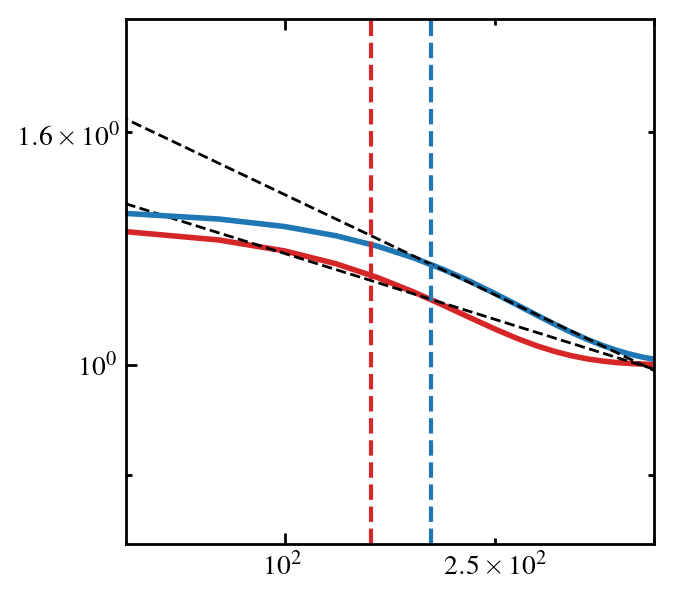

In [40]:
xmin = 50
mpl_setup('paper-1/2', aspect=4./4., fs=12)
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(xmin, 500)
ax.xaxis.set_minor_locator(plt.MaxNLocator(2)); ax.yaxis.set_minor_locator(plt.MaxNLocator(2))
# 60 pc 
y_comp1 = popt2[0] * np.exp(-radial_bins**2/2/popt2[1]**2)
y_comp2 = popt2[2] * np.exp(-radial_bins**2/2/popt2[3]**2)
y_comp3 = np.full(np.shape(radial_bins), fill_value=(1-popt2[0]-popt2[2]))
y_norm = 1+ y_comp2/y_comp3
# fit the power-law
x = np.log10(radial_bins); y = np.log10(y_norm)
popt = np.polyfit(x[3:10], y[3:10], deg=1)
print(popt)
y_fit = 10**(popt[0]*x + popt[1])
# 150pc
y_comp2 = popt2_150pc[2] * np.exp(-radial_bins**2/2/popt2_150pc[3]**2)
y_comp3 = np.full(np.shape(radial_bins), fill_value=(1-popt2_150pc[0]-popt2_150pc[2]))
y_norm_150pc = 1+ y_comp2/y_comp3
# fit the power-law
x = np.log10(radial_bins); y = np.log10(y_norm_150pc)
popt = np.polyfit(x[7:14], y[7:14], deg=1)
print(popt)
y_fit_150pc = 10**(popt[0]*x + popt[1])

ax.plot(radial_bins, y_norm, color='tab:red', lw=2)
ax.plot(radial_bins, y_fit, color='black', ls='dashed')
ax.plot(radial_bins, y_norm_150pc, color='tab:blue', lw=2)
ax.plot(radial_bins, y_fit_150pc, color='black', ls='dashed')

# fit the two curves with a power-law
ax.axvline(popt2[3], ls='dashed', lw=1.5, color='tab:red')
ax.axvline(popt2_150pc[3], ls='dashed', lw=1.5, color='tab:blue')

Calculate the ratio between the measured profile and kpc-scale intensity

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2328256395.py:5: RuntimeWarning: divide by zero encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2328256395.py:5: RuntimeWarning: invalid value encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2328256395.py:30: RuntimeWarning: divide by zero encountered in true_divide
  y_mod_1kpc = model_1kpc / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2328256395.py:30: RuntimeWarning: invalid value encountered in true_divide
  y_mod_1kpc = model_1kpc / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/2328256395.py:35: RuntimeWarning: invalid value encountered in true_divide
  Excs_clustering = np.nanmedian(y_real 

[-0.46968135  0.84845204]


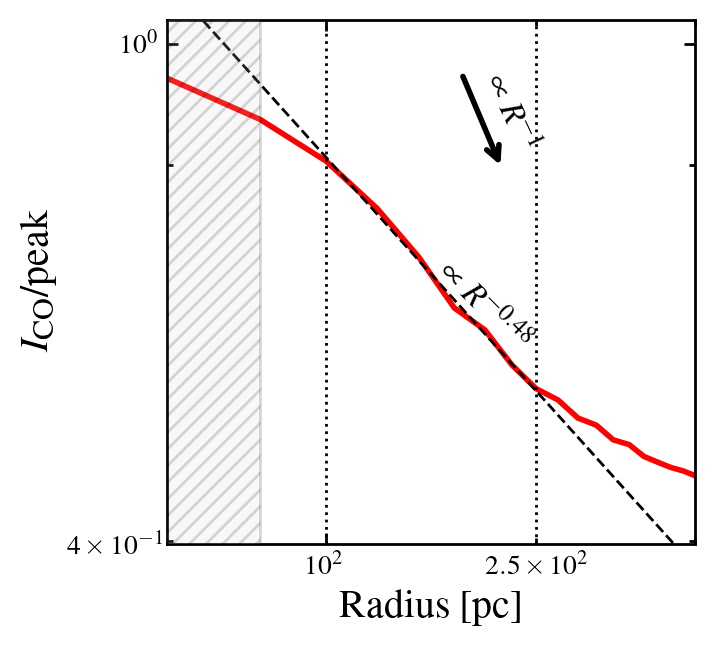

In [41]:

%matplotlib inline

radial_bins = gmc_stacked['radial_bins'][0]
real = np.array(gmc_stacked['radial_real_val'])
y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
real_median = np.nanmedian(real, axis=0)
y_real_median = np.nanmedian(y_real, axis=0)

peak_vals = np.array(gmc_stacked['peak_val'])
# peak_vals = real[:,0]
peak_int_corr = real * np.repeat(peak_vals[:,None], 80, axis=1)
peak_int_corr_med = np.nanmedian(peak_int_corr, axis=0)

from statsmodels.stats.weightstats import DescrStatsW
def weighted_median_2d_along_axis0(data, weights):
    """
    data: 2D array (n_samples, n_features)
    weights: 1D array of shape (n_samples,)
    Returns: 1D array of weighted medians for each column
    """
    data = np.asarray(data)
    weights = np.asarray(weights)
    return np.array([
        DescrStatsW(data[:, col], weights=weights).quantile(0.5)
        for col in range(data.shape[1])
    ])

# import the kpc-scale measurement
model_1kpc = np.array(gmc_stacked['radial_val_model_1kpc'])
y_mod_1kpc = model_1kpc / np.repeat(real[:,0][:, None], 80, axis=1)
model_1kpc_med = np.nanmedian(model_1kpc, axis=0)
y_mod_1kpc_med = np.nanmedian(y_mod_1kpc, axis=0)

# Calculate the ratio between the data and model
Excs_clustering = np.nanmedian(y_real / y_mod_1kpc, axis=0)

mpl_setup('paper-1/2', aspect=4./4., fs=12)
xmin = 50
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Radius [pc]')
ax.set_ylabel(r'$I_{\mathrm{CO}}$/peak')
# ax.set_ylabel(r'$I_{\mathrm{CO}} \times$ peak')
ax.set_xlim(xmin, 500)
ax.xaxis.set_minor_locator(plt.MaxNLocator(2)); ax.yaxis.set_minor_locator(plt.MaxNLocator(2))
plt.plot(radial_bins, y_real_median, color='red', lw=2)
ax.set_ylim()
# fit the straight part of the curve in log space
x = np.log10(radial_bins); y = np.log10(y_real_median)
popt = np.polyfit(x[4:10], y[4:10], deg=1)
print(popt)
y_fit = 10**(popt[0]*x + popt[1])
plt.plot(radial_bins, y_fit, color='black', ls='dashed')
ax.annotate(r'$\propto R^{-0.48}$', (0.6,0.45), xycoords='axes fraction', rotation=-45, ha='center', va='center')
# plot the expected slope
ax.annotate(
    '',  # no text
    xy=(180*1.2, 0.95/1.2),        # arrow tip
    xytext=(180, 0.95),      # arrow tail
    arrowprops=dict(
        arrowstyle='->', 
        color='black', 
        lw=2
    )
)
ax.annotate(r'$\propto R^{-1}$', (0.65,0.82), xycoords='axes fraction', rotation=-65, ha='center', va='center')
ax.axvline(radial_bins[4], ls='dotted', color='black')
ax.axvline(radial_bins[10], ls='dotted', color='black')

# plot the region of the beam
ax.fill_betweenx([0, 10], xmin, 75,  
                hatch='////',facecolor='lightgray',alpha=0.15,
                zorder=8,edgecolor=r'black',label=r'Beam')
plt.savefig('../plots/stacking_scale_free.png', bbox_inches='tight')

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/4054167665.py:12: RuntimeWarning: divide by zero encountered in log10
  x = np.log10(radial_bins); y = np.log10(y_60pc_median)


[-0.23460856  0.1181206 ]


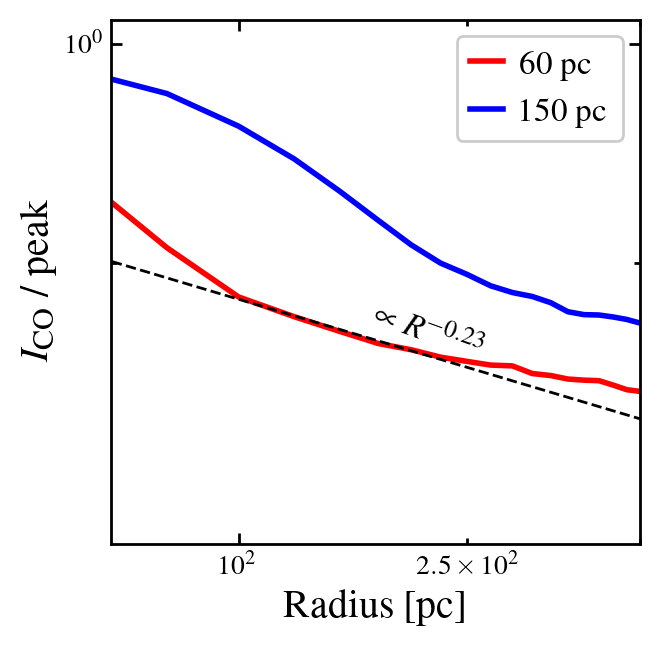

In [42]:
# at log scale 
mpl_setup('paper-1/2', aspect=4./4., fs=12)
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(60, 500)
ax.xaxis.set_minor_locator(plt.MaxNLocator(2)); ax.yaxis.set_minor_locator(plt.MaxNLocator(2))
plt.plot(radial_bins, y_60pc_median, color='red', lw=2, label='60 pc')
plt.plot(radial_bins, y_150pc_median, color='blue', lw=2, label='150 pc')
ax.set_ylabel(r'$I_{\mathrm{CO}}$ / peak'); ax.set_xlabel('Radius [pc]')
# fit a straight line
x = np.log10(radial_bins); y = np.log10(y_60pc_median)
popt = np.polyfit(x[4:10], y[4:10], deg=1)
print(popt)
y_fit = 10**(popt[0]*x + popt[1])
plt.plot(radial_bins, y_fit, color='black', ls='dashed')
ax.annotate(r'$\propto R^{-0.23}$', (0.6,0.4), xycoords='axes fraction', rotation=-20, ha='center', va='center')
plt.legend()
plt.savefig('../plots/stacking_log_60pc.png')

## Back-up analyses

### Compare the difference in data and model profiles among different environments

Check the difference between the spiral arm and interarm

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:28: RuntimeWarning: divide by zero encountered in true_divide
  frac = y_mod_elptc / y_real
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:9: RuntimeWarning: divide by zero encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:9: RuntimeWarning: invalid value encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)


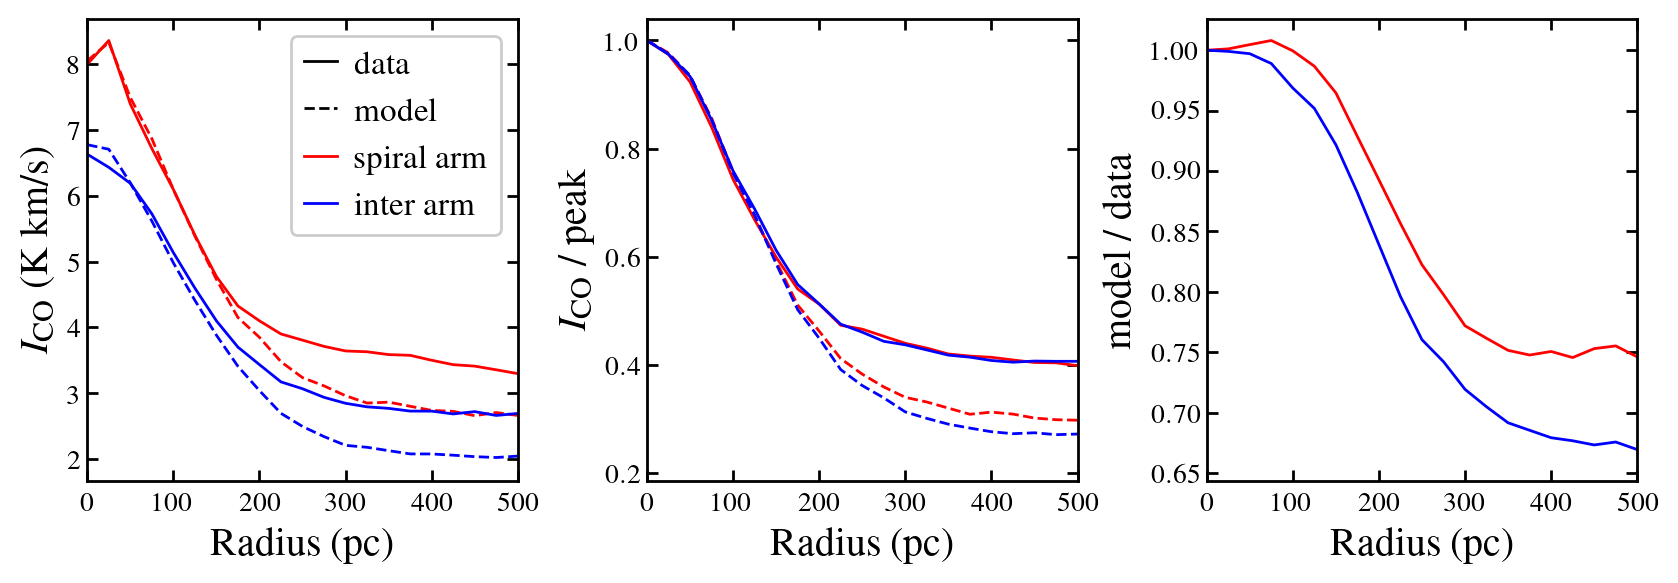

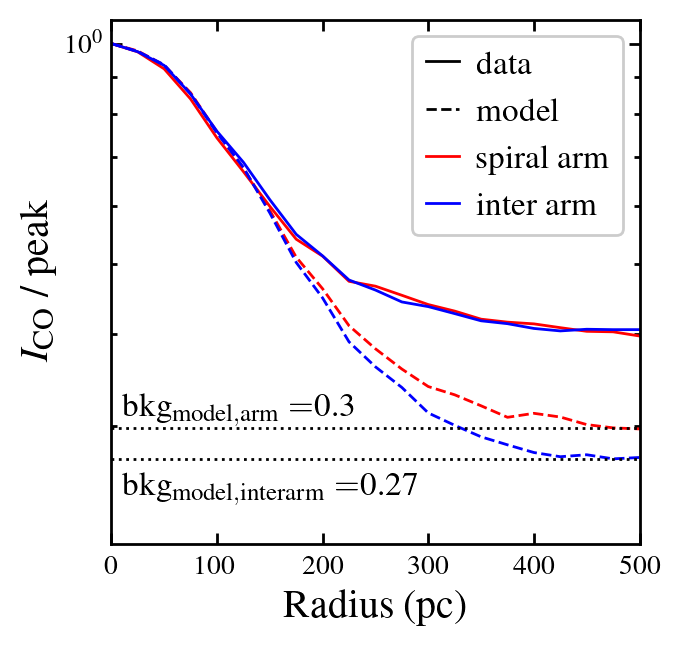

In [50]:
%matplotlib inline
# select GMCs in the arm
gmc_cats_arms = gmc_cats_new[gmc_cats_new['arm_lab']==1]
# select GMCs in the inter arm region
gmc_cats_intarms = gmc_cats_new[gmc_cats_new['arm_lab']==0]

def calc_rad_med(gmc_table):
    real = np.array(gmc_table['radial_real_val'])
    y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
    real_median = np.nanmedian(real, axis=0)
    y_real_median = np.nanmedian(y_real, axis=0)
    # model convolving with a fixed beam size
    model_150pc = np.array(gmc_table['radial_modelbeam_val'])
    y_mod_150pc = model_150pc / np.repeat(model_150pc[:,0][:, None], 80, axis=1)
    model_150pc_median = np.nanmedian(model_150pc, axis=0)
    y_mod_150pc_median = np.nanmedian(y_mod_150pc, axis=0)
    # model convolving with measured GMC size
    model_gmc_rad = np.array(gmc_table['radial_model_val'])
    y_mod_gmc_rad = model_gmc_rad / np.repeat(model_gmc_rad[:,0][:, None], 80, axis=1)
    model_gmc_rad_median = np.nanmedian(model_gmc_rad, axis=0)
    y_mod_gmc_rad_median = np.nanmedian(y_mod_gmc_rad, axis=0)
    # model convolving with GMC elliptical beam
    model_elptc = np.array(gmc_table['radial_model_elptc_val'])
    y_mod_elptc = model_elptc / np.repeat(model_elptc[:,0][:, None], 80, axis=1)
    model_elptc_median = np.nanmedian(model_elptc, axis=0)
    y_mod_elptc_median = np.nanmedian(y_mod_elptc, axis=0)
    # get the fraction
    frac = y_mod_elptc / y_real
    frac_med = np.nanmedian(frac, axis=0)

    return real_median, y_real_median, model_elptc_median, y_mod_elptc_median, frac_med

arm_median, y_arm_median, arm_mod_median, y_arm_mod_median, frac_arm_median = calc_rad_med(gmc_cats_arms)
intarm_median, y_intarm_median, intarm_mod_median, y_intarm_mod_median, frac_interarm_median = calc_rad_med(gmc_cats_intarms)

# plot the spiral arms and non-spiral arms
fig = plt.figure(figsize=(10,3))
ax = plt.subplot(131)
# ax.set_xscale('log'); ax.set_yscale('log')
ax.plot(gmc_cats_new['radial_bins'][0], arm_median, color='red')
ax.plot(gmc_cats_new['radial_bins'][0], arm_mod_median, color='red', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], intarm_median, color='blue')
ax.plot(gmc_cats_new['radial_bins'][0], intarm_mod_median, color='blue', ls='dashed')
ax.set_xlim(0, 500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ (K km/s)')

# create legend
plt.plot([],[], ls='solid', color='black', label='data')
plt.plot([],[], ls='dashed', color='black', label='model')
plt.plot([],[], ls='solid', color='red', label='spiral arm')
plt.plot([],[], ls='solid', color='blue', label='inter arm')
plt.legend()

ax = plt.subplot(132)
# ax.set_xscale('log'); ax.set_yscale('log')
ax.plot(gmc_cats_new['radial_bins'][0], y_arm_median, color='red')
ax.plot(gmc_cats_new['radial_bins'][0], y_arm_mod_median, color='red', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], y_intarm_median, color='blue')
ax.plot(gmc_cats_new['radial_bins'][0], y_intarm_mod_median, color='blue', ls='dashed')
ax.set_xlim(0,500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ / peak')

ax = plt.subplot(133)
# ax.set_xscale('log'); ax.set_yscale('log')
ax.plot(gmc_cats_new['radial_bins'][0], frac_arm_median , color='red')
ax.plot(gmc_cats_new['radial_bins'][0], frac_interarm_median, color='blue')
ax.set_xlim(0,500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel('model / data')

fig.subplots_adjust(wspace=0.3)
plt.savefig('../plots/GMC_stacking_spiral_arm.png', bbox_inches='tight', dpi=300)


mpl_setup('paper-1/2', aspect=4./4., fs=12)
fig = plt.figure()
ax = plt.subplot(111)
ax.set_yscale('log')
ax.tick_params(axis='y', which='minor', labelleft=False)

# create legend
plt.plot([],[], ls='solid', color='black', label='data')
plt.plot([],[], ls='dashed', color='black', label='model')
plt.plot([],[], ls='solid', color='red', label='spiral arm')
plt.plot([],[], ls='solid', color='blue', label='inter arm')
plt.legend()

# ax.set_xscale('log'); ax.set_yscale('log')
ax.plot(gmc_cats_new['radial_bins'][0], y_arm_median, color='red')
ax.plot(gmc_cats_new['radial_bins'][0], y_arm_mod_median, color='red', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], y_intarm_median, color='blue')
ax.plot(gmc_cats_new['radial_bins'][0], y_intarm_mod_median, color='blue', ls='dashed')
ax.set_xlim(0,500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ / peak', va='bottom')

# label the horizontal lines
ax.axhline(0.298, ls='dotted', color='black')
ax.annotate(r'$\mathrm{bkg_{model, arm}}=$0.3', (10, 0.31), xycoords='data')
ax.axhline(0.27, ls='dotted', color='black')
ax.annotate(r'$\mathrm{bkg_{model, interarm}}=$0.27', (10, 0.26), xycoords='data', va='top')

plt.savefig('../plots/GMC_stacking_spiral_arm_onepanel.png', bbox_inches='tight', dpi=300)

Bin the radial profile by the galactic radius

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:28: RuntimeWarning: divide by zero encountered in true_divide
  frac = y_mod_elptc / y_real
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:9: RuntimeWarning: divide by zero encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:9: RuntimeWarning: invalid value encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)


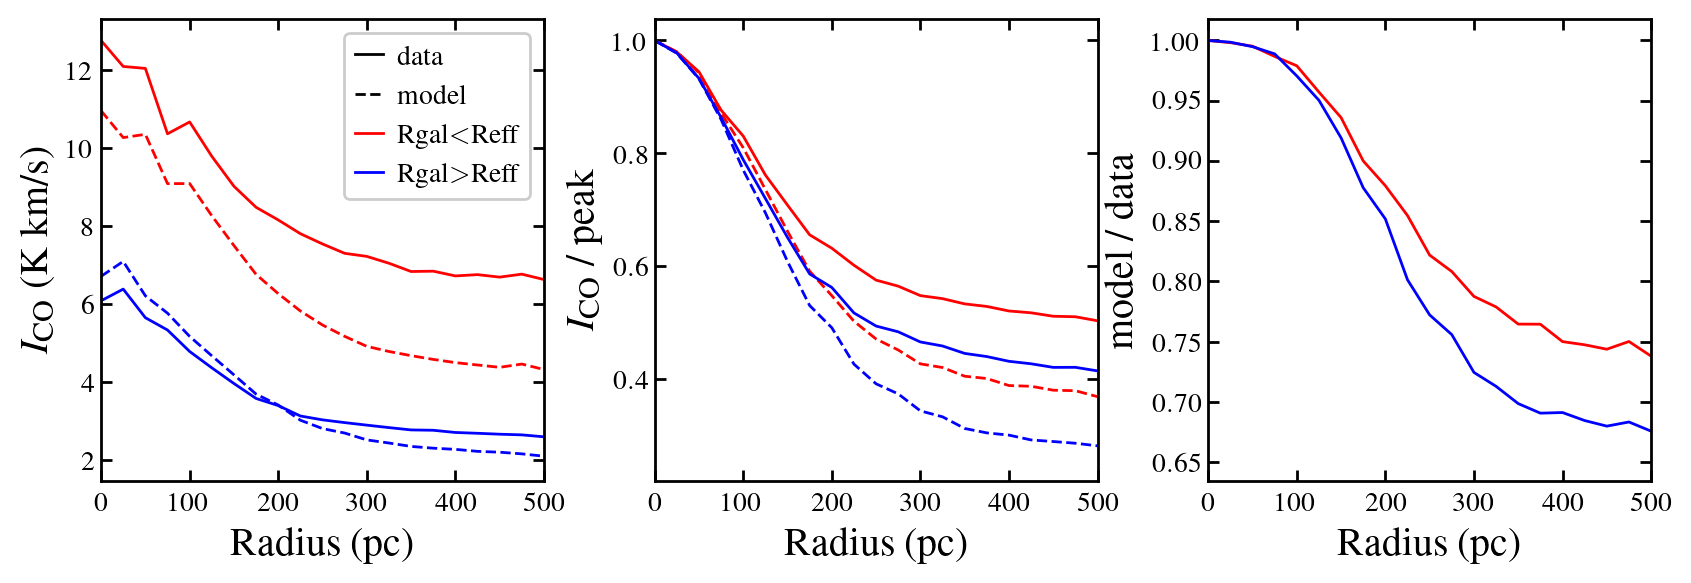

In [51]:
# Calculate the GMC radius in the unit of the effective radius
gmc_cats_new['RGAL_reff'] = np.full(np.shape(gmc_cats_new['GALAXY']), fill_value=np.nan)

for this_source in source_list:
    this_size = np.array(deets_dict[this_source]['size_reff'])
    row_idx = np.where(gmc_cats_new['GALAXY'] == this_source)
    gmc_cats_new['RGAL_reff'][row_idx] =  gmc_cats_new['RGAL_DEG'][row_idx]*3600./this_size

gmc_cats_center = gmc_cats_new[gmc_cats_new['RGAL_reff']<=0.5]
gmc_cats_1reff = gmc_cats_new[(gmc_cats_new['RGAL_reff']<=1)]
gmc_cats_1p5reff = gmc_cats_new[(gmc_cats_new['RGAL_reff']>1) & (gmc_cats_new['RGAL_reff']<=1.5)]
gmc_cats_2reff = gmc_cats_new[(gmc_cats_new['RGAL_reff']>1)]

center_data, y_center_data, center_mod, y_center_mod, frac_center = calc_rad_med(gmc_cats_center)
reff_1_data, y_reff_1_data, reff_1_mod, y_reff_1_mod, frac_1reff = calc_rad_med(gmc_cats_1reff)
reff_1p5_data, y_reff_1p5_data, reff_1p5_mod, y_reff_1p5_mod, frac_1p5reff = calc_rad_med(gmc_cats_1p5reff)
reff_2_data, y_reff_2_data, reff_2_mod, y_reff_2_mod, frac_2reff = calc_rad_med(gmc_cats_2reff)

fig = plt.figure(figsize=(10,3))
ax = plt.subplot(131)
# ax.plot(gmc_cats_new['radial_bins'][0], center_data, color='red')
ax.plot(gmc_cats_new['radial_bins'][0], reff_1_data, color='red')
# ax.plot(gmc_cats_new['radial_bins'][0], reff_1p5_data, color='magenta')
ax.plot(gmc_cats_new['radial_bins'][0], reff_2_data, color='blue')

# ax.plot(gmc_cats_new['radial_bins'][0], center_mod, color='red', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], reff_1_mod, color='red', ls='dashed')
# ax.plot(gmc_cats_new['radial_bins'][0], reff_1p5_mod, color='magenta', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], reff_2_mod, color='blue', ls='dashed')

ax.set_xlim(0, 500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ (K km/s)')

# create legend
plt.plot([],[], ls='solid', color='black', label='data')
plt.plot([],[], ls='dashed', color='black', label='model')
plt.plot([],[], ls='solid', color='red', label=r'Rgal$<$Reff')
plt.plot([],[], ls='solid', color='blue', label=r'Rgal$>$Reff')
plt.legend(fontsize=10)

ax = plt.subplot(132)
ax.plot(gmc_cats_new['radial_bins'][0], y_reff_1_data, color='red')
ax.plot(gmc_cats_new['radial_bins'][0], y_reff_1_mod, color='red', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], y_reff_2_data, color='blue')
ax.plot(gmc_cats_new['radial_bins'][0], y_reff_2_mod, color='blue', ls='dashed')
ax.set_xlim(0,500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ / peak')

ax = plt.subplot(133)
ax.plot(gmc_cats_new['radial_bins'][0], frac_1reff , color='red')
ax.plot(gmc_cats_new['radial_bins'][0], frac_2reff, color='blue')
ax.set_xlim(0,500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel('model / data')

fig.subplots_adjust(wspace=0.25)
plt.savefig('../plots/GMC_stacking_radial_dependance.png', bbox_inches='tight', dpi=300)


Divide by galaxy 1kpc CO intensity

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:9: RuntimeWarning: divide by zero encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:9: RuntimeWarning: invalid value encountered in true_divide
  y_real = real / np.repeat(real[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1461915460.py:28: RuntimeWarning: divide by zero encountered in true_divide
  frac = y_mod_elptc / y_real


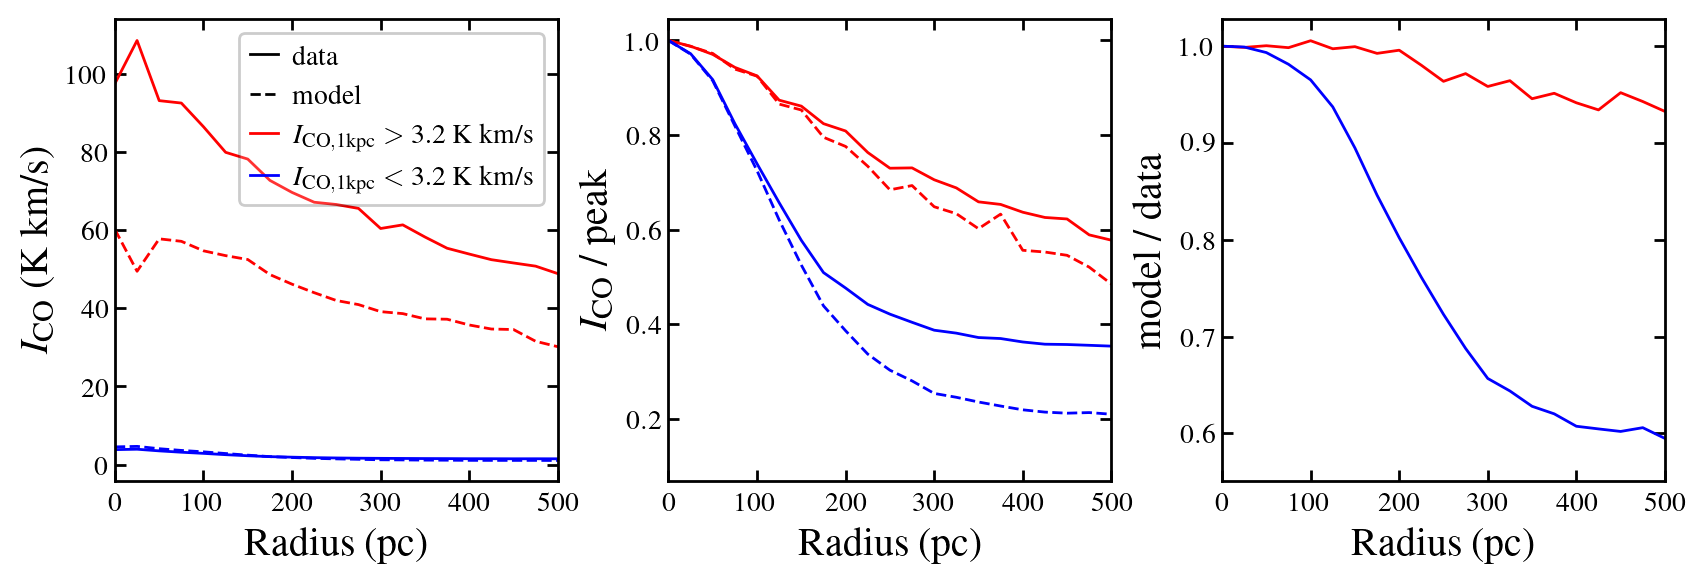

In [52]:
# select GMCs in gas concentration regions
gmc_cats_high = gmc_cats_new[gmc_cats_new['peak_1kpc_val']>10**1.5]
# select GMCs in less gas concentration regions
gmc_cats_low = gmc_cats_new[gmc_cats_new['peak_1kpc_val']<=10**0.5]

high_median, y_high_median, high_mod_median, y_high_mod_median, frac_high_median = calc_rad_med(gmc_cats_high)
low_median, y_low_median, low_mod_median, y_low_mod_median, frac_low_median = calc_rad_med(gmc_cats_low)

fig = plt.figure(figsize=(10,3))
ax = plt.subplot(131)
# ax.plot(gmc_cats_new['radial_bins'][0], center_data, color='red')
ax.plot(gmc_cats_new['radial_bins'][0], high_median, color='red')
# ax.plot(gmc_cats_new['radial_bins'][0], reff_1p5_data, color='magenta')
ax.plot(gmc_cats_new['radial_bins'][0], low_median, color='blue')

# ax.plot(gmc_cats_new['radial_bins'][0], center_mod, color='red', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], high_mod_median, color='red', ls='dashed')
# ax.plot(gmc_cats_new['radial_bins'][0], reff_1p5_mod, color='magenta', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], low_mod_median, color='blue', ls='dashed')

ax.set_xlim(0, 500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ (K km/s)')

# create legend
plt.plot([],[], ls='solid', color='black', label='data')
plt.plot([],[], ls='dashed', color='black', label='model')
plt.plot([],[], ls='solid', color='red', label=r'$I_{\mathrm{CO, 1kpc}}>$ 3.2 K km/s')
plt.plot([],[], ls='solid', color='blue', label=r'$I_{\mathrm{CO, 1kpc}}<$ 3.2 K km/s')
plt.legend(fontsize=10)

ax = plt.subplot(132)
ax.plot(gmc_cats_new['radial_bins'][0], y_high_median, color='red')
ax.plot(gmc_cats_new['radial_bins'][0], y_high_mod_median, color='red', ls='dashed')
ax.plot(gmc_cats_new['radial_bins'][0], y_low_median, color='blue')
ax.plot(gmc_cats_new['radial_bins'][0], y_low_mod_median, color='blue', ls='dashed')
ax.set_xlim(0,500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$I_{\mathrm{CO}}$ / peak')

ax = plt.subplot(133)
ax.plot(gmc_cats_new['radial_bins'][0], frac_high_median , color='red')
ax.plot(gmc_cats_new['radial_bins'][0], frac_low_median, color='blue')
ax.set_xlim(0,500)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel('model / data')

fig.subplots_adjust(wspace=0.25)
plt.savefig('../plots/GMC_stacking_Ico_dependance.png', bbox_inches='tight', dpi=300)

Try to calculate the ratio of model and single model profile

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/567078284.py:2: RuntimeWarning: invalid value encountered in true_divide
  y_mod_single_gmc = model_single_gmc / np.repeat(model_single_gmc[:,0][:, None], 80, axis=1)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/567078284.py:5: RuntimeWarning: divide by zero encountered in true_divide
  real = np.array(gmc_stacked['radial_real_val']); y_real = real / np.repeat(real[:,0][:,None], 80, axis=1); y_real_med = np.nanmedian(y_real, axis=0)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/567078284.py:5: RuntimeWarning: invalid value encountered in true_divide
  real = np.array(gmc_stacked['radial_real_val']); y_real = real / np.repeat(real[:,0][:,None], 80, axis=1); y_real_med = np.nanmedian(y_real, axis=0)


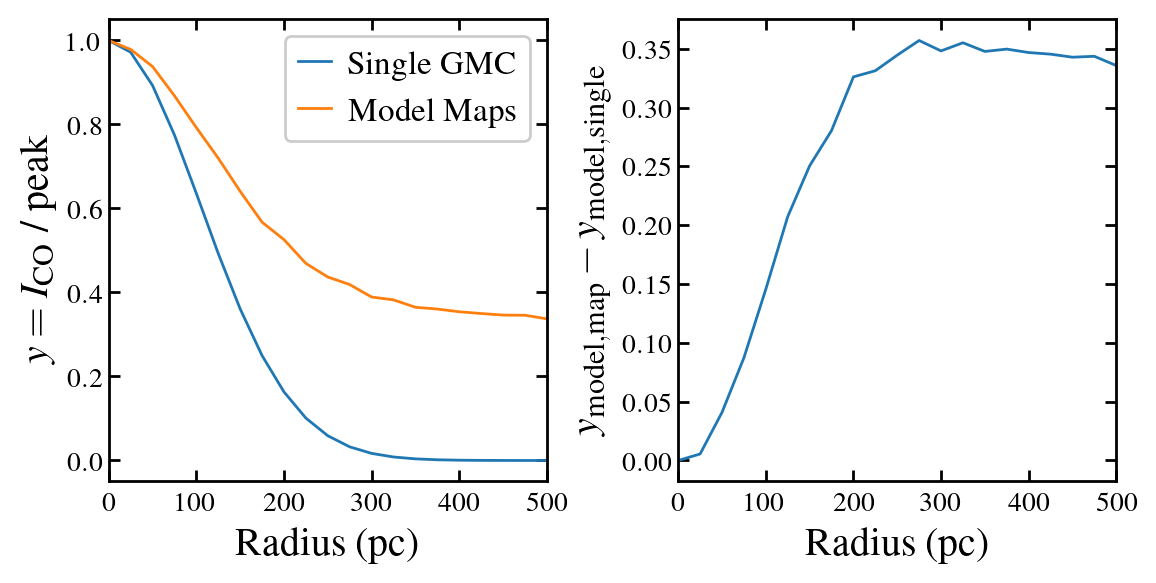

In [53]:
model_single_gmc = np.array(gmc_stacked['radial_singlgmc_val'])
y_mod_single_gmc = model_single_gmc / np.repeat(model_single_gmc[:,0][:, None], 80, axis=1)
y_mod_single_med = np.nanmedian(y_mod_single_gmc, axis=0)

real = np.array(gmc_stacked['radial_real_val']); y_real = real / np.repeat(real[:,0][:,None], 80, axis=1); y_real_med = np.nanmedian(y_real, axis=0)
model_elptc = np.array(gmc_stacked['radial_model_elptc_val']); y_mod_map = model_elptc / np.repeat(model_elptc[:,0][:,None], 80, axis=1)
y_mod_map_med = np.nanmedian(y_mod_map, axis=0)

y_mod_combine = y_mod_single_gmc + y_real - y_mod_map; y_mod_combine_med = np.nanmedian(y_mod_combine, axis=0)
ratio = y_real / y_mod_combine; ratio_med = np.nanmedian(ratio, axis=0)
model_comp = y_mod_map - y_mod_single_gmc; mod_comp_med = np.nanmedian(model_comp, axis=0)

fig = plt.figure(figsize=(6.5,3))
ax = plt.subplot(121)
plt.xlim(0, 500)
plt.plot(gmc_stacked['radial_bins'][0], y_mod_single_med, label='Single GMC')
plt.plot(gmc_stacked['radial_bins'][0], y_mod_map_med, label='Model Maps')
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$y=I_{\mathrm{CO}}$ / peak')
plt.legend()

ax = plt.subplot(122)
plt.xlim(0,500)
# plt.plot(gmc_stacked['radial_bins'][0], y_real_med)
# plt.plot(gmc_stacked['radial_bins'][0], y_mod_combine_med)
plt.plot(gmc_stacked['radial_bins'][0], mod_comp_med)
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$y_{\mathrm{model, map}} - y_{\mathrm{model, single}}$')

plt.subplots_adjust(wspace=0.3)
plt.savefig('../plots/GMC_stacking_clustering.png', bbox_inches='tight', dpi=300)

Environmental impact on the clustering.

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52139/1923385582.py:9: RuntimeWarning: invalid value encountered in true_divide
  y_mod_single_gmc = model_single_gmc / np.repeat(model_single_gmc[:,0][:, None], 80, axis=1)


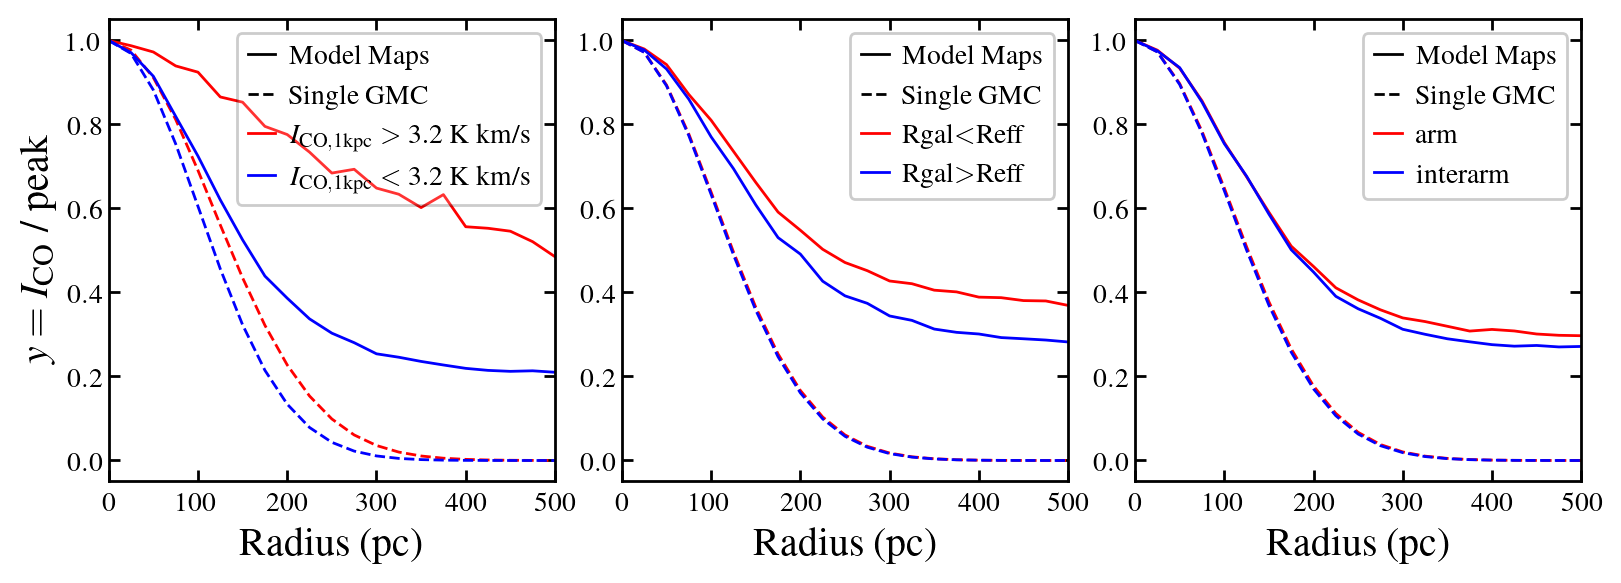

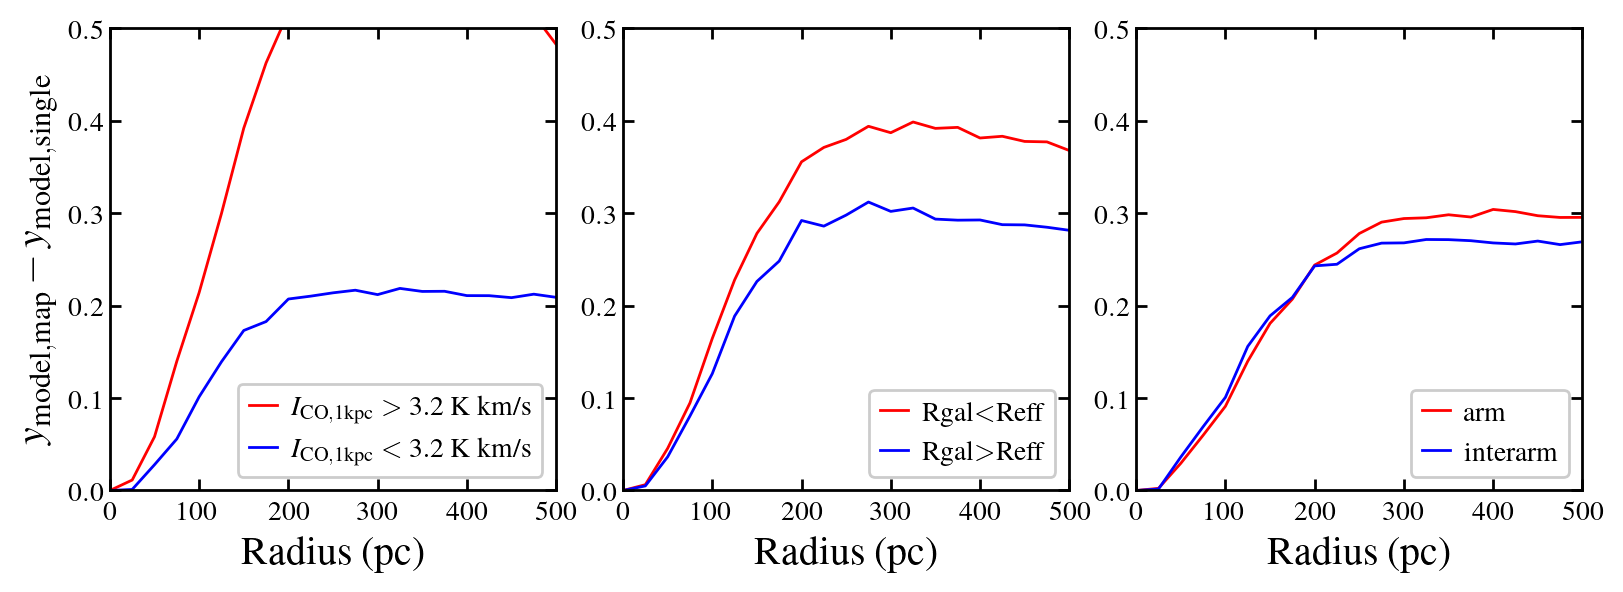

In [54]:
def calc_map_single_offsets(gmc_table):
    # model convolving with GMC elliptical beam
    model_map = np.array(gmc_table['radial_model_elptc_val'])
    y_mod_map = model_map / np.repeat(model_map[:,0][:, None], 80, axis=1)
    model_map_median = np.nanmedian(model_map, axis=0)
    y_mod_map_med = np.nanmedian(y_mod_map, axis=0)
    # get the profile of single GMCs
    model_single_gmc = np.array(gmc_table['radial_singlgmc_val'])
    y_mod_single_gmc = model_single_gmc / np.repeat(model_single_gmc[:,0][:, None], 80, axis=1)
    y_mod_single_med = np.nanmedian(y_mod_single_gmc, axis=0)
    # get the offsets
    mod_neighb = y_mod_map - y_mod_single_gmc
    mod_neighb_med = np.nanmedian(mod_neighb, axis=0) 


    return y_mod_map_med, y_mod_single_med, mod_neighb_med

# Divide the catalog by the kpc-scale CO intensity
high_mod_map, high_mod_single, high_offsets = calc_map_single_offsets(gmc_cats_high)
low_mod_map, low_mod_single, low_offsets = calc_map_single_offsets(gmc_cats_low)

# Divide the catalog by the inner and outer region
inner_mod_map, inner_mod_single, inner_offsets = calc_map_single_offsets(gmc_cats_1reff)
outer_mod_map, outer_mod_single, outer_offsets = calc_map_single_offsets(gmc_cats_2reff)

# Divide the catalog by spiral arm and non-spiral arm
arm_mod_map, arm_mod_single, arm_offsets = calc_map_single_offsets(gmc_cats_arms)
interarm_mod_map, interarm_mod_single, interarm_offsets = calc_map_single_offsets(gmc_cats_intarms)

fig = plt.figure(figsize=(9.5,3))
ax = plt.subplot(131)
# create legend
ax.plot([],[], ls='solid', color='black', label='Model Maps')
ax.plot([],[], ls='dashed', color='black', label='Single GMC')
ax.plot([],[], ls='solid', color='red', label=r'$I_{\mathrm{CO, 1kpc}}>$ 3.2 K km/s')
ax.plot([],[], ls='solid', color='blue', label=r'$I_{\mathrm{CO, 1kpc}}<$ 3.2 K km/s')
ax.legend(fontsize=10)

plt.xlim(0, 500)
plt.plot(gmc_stacked['radial_bins'][0], high_mod_single, ls='dashed', color='red')
plt.plot(gmc_stacked['radial_bins'][0], high_mod_map, ls='solid', color='red')
plt.plot(gmc_stacked['radial_bins'][0], low_mod_single, ls='dashed', color='blue')
plt.plot(gmc_stacked['radial_bins'][0], low_mod_map, ls='solid', color='blue')
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$y=I_{\mathrm{CO}}$ / peak')

ax = plt.subplot(132)
plt.xlim(0,500)
plt.plot(gmc_stacked['radial_bins'][0], inner_mod_single, ls='dashed', color='red')
plt.plot(gmc_stacked['radial_bins'][0], inner_mod_map, ls='solid', color='red')
plt.plot(gmc_stacked['radial_bins'][0], outer_mod_single, ls='dashed', color='blue')
plt.plot(gmc_stacked['radial_bins'][0], outer_mod_map, ls='solid', color='blue')
ax.set_xlabel('Radius (pc)')
# create legend
plt.plot([],[], ls='solid', color='black', label='Model Maps')
plt.plot([],[], ls='dashed', color='black', label='Single GMC')
plt.plot([],[], ls='solid', color='red', label=r'Rgal$<$Reff')
plt.plot([],[], ls='solid', color='blue', label=r'Rgal$>$Reff')
plt.legend(fontsize=10)

ax = plt.subplot(133)
plt.xlim(0,500)
plt.plot(gmc_stacked['radial_bins'][0], arm_mod_single, ls='dashed', color='red')
plt.plot(gmc_stacked['radial_bins'][0], arm_mod_map, ls='solid', color='red')
plt.plot(gmc_stacked['radial_bins'][0], interarm_mod_single, ls='dashed', color='blue')
plt.plot(gmc_stacked['radial_bins'][0], interarm_mod_map, ls='solid', color='blue')
ax.set_xlabel('Radius (pc)')

# create legend
plt.plot([],[], ls='solid', color='black', label='Model Maps')
plt.plot([],[], ls='dashed', color='black', label='Single GMC')
plt.plot([],[], ls='solid', color='red', label=r'arm')
plt.plot([],[], ls='solid', color='blue', label=r'interarm')
plt.legend(fontsize=10)

plt.subplots_adjust(wspace=0.15)
plt.savefig('../plots/GMC_clustering_evn1.png', bbox_inches='tight', dpi=300)

fig = plt.figure(figsize=(9.5, 3))

ax = plt.subplot(131)
plt.xlim(0,500); plt.ylim(0, 0.5)
plt.plot(gmc_stacked['radial_bins'][0], high_offsets, color='red', label=r'$I_{\mathrm{CO, 1kpc}}>$ 3.2 K km/s')
plt.plot(gmc_stacked['radial_bins'][0], low_offsets, color='blue', label=r'$I_{\mathrm{CO, 1kpc}}<$ 3.2 K km/s')
ax.set_xlabel('Radius (pc)'); ax.set_ylabel(r'$y_{\mathrm{model, map}} - y_{\mathrm{model, single}}$')
plt.legend(fontsize=10)

ax = plt.subplot(132)
plt.xlim(0,500); plt.ylim(0, 0.5)
plt.plot(gmc_stacked['radial_bins'][0], inner_offsets, color='red', label=r'Rgal$<$Reff')
plt.plot(gmc_stacked['radial_bins'][0], outer_offsets, color='blue', label=r'Rgal$>$Reff')
ax.set_xlabel('Radius (pc)')
plt.legend(fontsize=10, loc='lower right')

ax = plt.subplot(133)
plt.xlim(0,500); plt.ylim(0, 0.5)
plt.plot(gmc_stacked['radial_bins'][0], arm_offsets, color='red', label=r'arm')
plt.plot(gmc_stacked['radial_bins'][0], interarm_offsets, color='blue', label=r'interarm')
ax.set_xlabel('Radius (pc)')
plt.legend(fontsize=10, loc='lower right')

plt.subplots_adjust(wspace=0.15)
plt.savefig('../plots/GMC_clustering_evn2.png', bbox_inches='tight', dpi=300)

## Compare the stacking excess profile from different resolutions and sensitivities

In [56]:
source_list_90pc = get_source_list('../cross_90pc_hi_results')

gmc_90pc_stacked = Table()
for i, this_source in enumerate(source_list_90pc):
    infile_name = '../cloud_radial_profile/'+this_source+'_90pc_hi_cat.fits'
    gmc_rad_tabl = Table.read(infile_name)
    gmc_90pc_stacked = vstack([gmc_90pc_stacked, gmc_rad_tabl])

source_list_lo = get_source_list('../cross_results')
gmc_lo_stacked = Table()
for i, this_source in enumerate(source_list_lo):
    infile_name = '../cloud_radial_profile/'+this_source+'_150pc_hi_cat.fits'
    gmc_rad_tabl = Table.read(infile_name)
    gmc_lo_stacked = vstack([gmc_lo_stacked, gmc_rad_tabl])

(-98.75, 500.0)

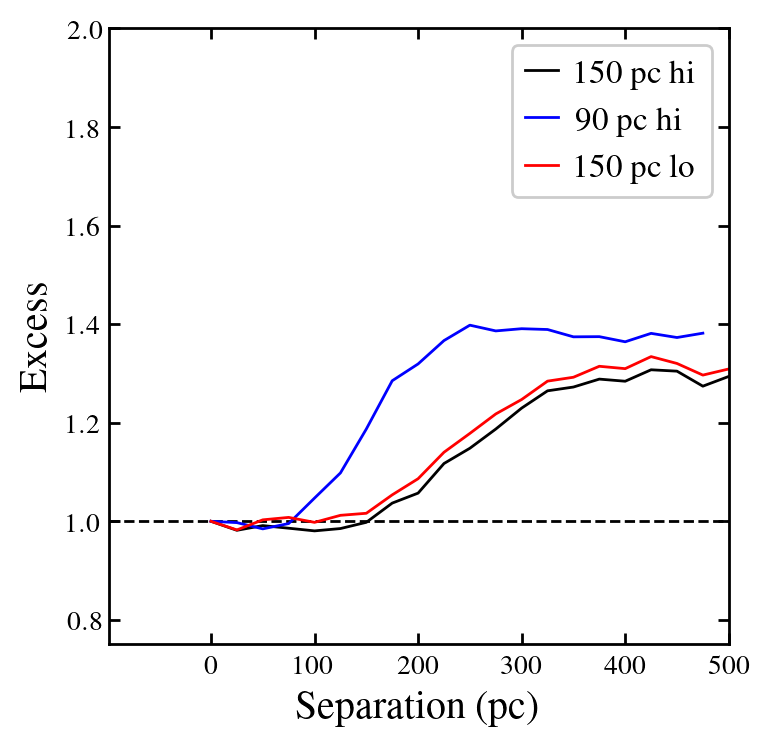

In [57]:
fig = plt.figure(figsize=(4,4))
ax = plt.subplot(111)
ax.set_ylim(0.75, 2)
ax.axhline(1.0, ls='dashed', color='black')
real_median = np.nanmedian(np.array(gmc_stacked['radial_real_val']), axis=0); y_real_median = real_median / real_median[0]
model_median = np.nanmedian(np.array(gmc_stacked['radial_model_val']), axis=0); y_model_median = model_median / model_median[0]
excess_median = y_real_median / y_model_median
plt.plot(gmc_stacked['radial_bins'][0], excess_median, color='black', label='150 pc hi')
real_median = np.nanmedian(np.array(gmc_90pc_stacked['radial_real_val']), axis=0); y_real_median = real_median / real_median[0]
model_median = np.nanmedian(np.array(gmc_90pc_stacked['radial_model_val']), axis=0); y_model_median = model_median / model_median[0]
excess_median = y_real_median / y_model_median
plt.plot(gmc_90pc_stacked['radial_bins'][0], excess_median, color='blue', label='90 pc hi')

real_median = np.nanmedian(np.array(gmc_lo_stacked['radial_real_val']), axis=0); y_real_median = real_median / real_median[0]
model_median = np.nanmedian(np.array(gmc_lo_stacked['radial_model_val']), axis=0); y_model_median = model_median / model_median[0]
excess_median = y_real_median / y_model_median
plt.plot(gmc_lo_stacked['radial_bins'][0], excess_median, color='red', label='150 pc lo')

plt.ylabel('Excess')
plt.xlabel('Separation (pc)')
plt.legend()
ax.set_xlim(right=500)